# Robust Crop Disease Screening Using Explainable Deep Learning

## Project Overview

This research project develops a deep-learning-based crop disease screening system using the PlantVillage dataset. The study focuses not only on classification performance but also on model explainability, robustness, domain shift, and potential dataset bias.

## Research Objectives

- Develop an effective deep-learning model for crop disease classification.
- Evaluate model performance using comprehensive classification metrics.
- Investigate whether the model focuses on disease-relevant regions using Explainable AI (XAI).
- Evaluate model robustness under real-world domain shift using an external dataset where appropriate.
- Analyze errors, dataset bias, and possible shortcut learning.

## Primary Dataset

**Dataset:** PlantVillage  
**Hugging Face ID:** `mohanty/PlantVillage`  
**Approximate Size:** 54,306 images  
**Coverage:** 14 crop species and 26 disease classes, including healthy classes.

## Research Focus

The main research areas are:

1. Crop disease classification
2. Explainable AI
3. Domain-shift robustness
4. Dataset bias and shortcut analysis
5. Error analysis
6. Ablation studies

## Important Scientific Note

This project focuses on **crop disease screening**. It will not claim "early disease detection" because the PlantVillage dataset does not provide scientifically validated disease-progression stages such as early, moderate, or severe.

## Experimental Principle

All experiments will be conducted using reproducible procedures with careful attention to data leakage, train/validation/test separation, model evaluation, and experimental evidence.

**Working Environment:** Google Colab with GPU

**Project Standard:** Technically sound, reproducible, and publication-oriented research.



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

##Import Necessary Libraries

In [ ]:
# Core Python libraries
import os
import sys
import random
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Image processing
from PIL import Image

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Torchvision
import torchvision
import torchvision.transforms as transforms
from torchvision import models

print("Libraries imported successfully.")

Libraries imported successfully.


##Verify Colab Environment and GPU

In [ ]:
print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")
else:
    print("WARNING: GPU is not available. Please enable GPU runtime in Colab.")

Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
CUDA available: True
GPU: Tesla T4
CUDA version: 12.8
GPU memory: 14.56 GB


In [ ]:
# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Random seed:", SEED)
print("Device:", device)

Random seed: 42
Device: cuda


##Define Project Directory Structure

In [ ]:
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Main project directory
PROJECT_DIR = "/content/drive/MyDrive/Robust_Crop_Disease_Screening"

# Create required directories
directories = [
    PROJECT_DIR,
    os.path.join(PROJECT_DIR, "data"),
    os.path.join(PROJECT_DIR, "data", "raw"),
    os.path.join(PROJECT_DIR, "data", "processed"),
    os.path.join(PROJECT_DIR, "models"),
    os.path.join(PROJECT_DIR, "results"),
    os.path.join(PROJECT_DIR, "results", "figures"),
    os.path.join(PROJECT_DIR, "results", "metrics"),
    os.path.join(PROJECT_DIR, "explainability"),
    os.path.join(PROJECT_DIR, "experiments"),
]

for directory in directories:
    os.makedirs(directory, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Directory structure created successfully.")

Mounted at /content/drive
Project directory: /content/drive/MyDrive/Robust_Crop_Disease_Screening
Directory structure created successfully.


##Install Required Dataset Library

In [ ]:
!pip install -q datasets

##Import and Verify Hugging Face Datasets

In [ ]:
from datasets import load_dataset

print("Hugging Face Datasets imported successfully.")

Hugging Face Datasets imported successfully.


##Inspect the Hugging Face Repository

In [ ]:
from huggingface_hub import list_repo_files

repo_files = list_repo_files(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset"
)

print("Total repository files:", len(repo_files))
print("\nFirst 30 files:")
for file in repo_files[:30]:
    print(file)

Total repository files: 11

First 30 files:
.gitattributes
README.md
data.zip
leaf_grouping/leaf-map.json
plant_village.py
splits/color_test.txt
splits/color_train.txt
splits/grayscale_test.txt
splits/grayscale_train.txt
splits/segmented_test.txt
splits/segmented_train.txt


##Download the Dataset Archive

In [ ]:
from huggingface_hub import hf_hub_download

DATA_ZIP_PATH = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    filename="data.zip",
    repo_type="dataset",
    local_dir=os.path.join(PROJECT_DIR, "data", "raw")
)

print("Dataset archive downloaded successfully.")
print("Path:", DATA_ZIP_PATH)
print("Size (GB):", round(os.path.getsize(DATA_ZIP_PATH) / (1024**3), 2))

data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

Dataset archive downloaded successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/data/raw/data.zip
Size (GB): 2.03


##Extract PlantVillage Dataset

In [1]:
import zipfile

EXTRACT_DIR = os.path.join(PROJECT_DIR, "data", "raw", "plantvillage")

if not os.path.exists(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(DATA_ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully.")
print("Extraction directory:", EXTRACT_DIR)

# Show top-level extracted contents
print("\nTop-level contents:")
for item in os.listdir(EXTRACT_DIR):
    print("-", item)

NameError: name 'os' is not defined

In [ ]:
# Check how much of the dataset was extracted before interruption

if os.path.exists(EXTRACT_DIR):
    extracted_files = 0
    extracted_dirs = 0

    for root, dirs, files in os.walk(EXTRACT_DIR):
        extracted_dirs += len(dirs)
        extracted_files += len(files)

    print("Extraction directory exists:", True)
    print("Extracted files:", extracted_files)
    print("Extracted directories:", extracted_dirs)
else:
    print("Extraction directory exists:", False)

Extraction directory exists: True
Extracted files: 82416
Extracted directories: 61


##Inspect Extracted Dataset Structure

In [ ]:
# Inspect the extracted PlantVillage structure

print("Top-level contents:")
for item in sorted(os.listdir(EXTRACT_DIR)):
    item_path = os.path.join(EXTRACT_DIR, item)
    if os.path.isdir(item_path):
        print(f"[DIR]  {item}")
    else:
        print(f"[FILE] {item}")

print("\nDirectory summary:")

for root, dirs, files in os.walk(EXTRACT_DIR):
    if files:
        relative_path = os.path.relpath(root, EXTRACT_DIR)
        print(f"{relative_path}: {len(files)} files")

Top-level contents:
[DIR]  raw

Directory summary:
raw/color/Raspberry___healthy: 371 files
raw/color/Potato___Late_blight: 1000 files
raw/color/Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513 files
raw/color/Tomato___Early_blight: 1000 files
raw/color/Apple___healthy: 1645 files
raw/color/Tomato___Tomato_mosaic_virus: 373 files
raw/color/Corn_(maize)___Northern_Leaf_Blight: 985 files
raw/color/Corn_(maize)___Common_rust_: 1192 files
raw/color/Corn_(maize)___healthy: 1162 files
raw/color/Cherry_(including_sour)___healthy: 854 files
raw/color/Orange___Haunglongbing_(Citrus_greening): 5507 files
raw/color/Soybean___healthy: 5090 files
raw/color/Strawberry___Leaf_scorch: 1109 files
raw/color/Tomato___healthy: 1591 files
raw/color/Grape___Esca_(Black_Measles): 1383 files
raw/color/Grape___Black_rot: 1180 files
raw/color/Cherry_(including_sour)___Powdery_mildew: 1052 files
raw/color/Tomato___Target_Spot: 1404 files
raw/color/Peach___healthy: 360 files
raw/color/Potato___Early_blight

##Verify Color Dataset Against Official Split

In [ ]:
# Paths to the official split files
TRAIN_SPLIT_PATH = os.path.join(
    os.path.dirname(DATA_ZIP_PATH),
    "color_train.txt"
)

TEST_SPLIT_PATH = os.path.join(
    os.path.dirname(DATA_ZIP_PATH),
    "color_test.txt"
)

print("Checking for split files...")

print("Train split exists:", os.path.exists(TRAIN_SPLIT_PATH))
print("Test split exists:", os.path.exists(TEST_SPLIT_PATH))

if os.path.exists(TRAIN_SPLIT_PATH):
    with open(TRAIN_SPLIT_PATH, "r") as f:
        train_entries = [line.strip() for line in f if line.strip()]

    print("Training entries:", len(train_entries))

if os.path.exists(TEST_SPLIT_PATH):
    with open(TEST_SPLIT_PATH, "r") as f:
        test_entries = [line.strip() for line in f if line.strip()]

    print("Test entries:", len(test_entries))

Checking for split files...
Train split exists: False
Test split exists: False


In [ ]:
from huggingface_hub import hf_hub_download

SPLIT_DIR = os.path.join(PROJECT_DIR, "data", "raw", "splits")
os.makedirs(SPLIT_DIR, exist_ok=True)

TRAIN_SPLIT_PATH = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    filename="splits/color_train.txt",
    repo_type="dataset",
    local_dir=SPLIT_DIR
)

TEST_SPLIT_PATH = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    filename="splits/color_test.txt",
    repo_type="dataset",
    local_dir=SPLIT_DIR
)

print("Official color split files downloaded successfully.")
print("Train split:", TRAIN_SPLIT_PATH)
print("Test split:", TEST_SPLIT_PATH)

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

Official color split files downloaded successfully.
Train split: /content/drive/MyDrive/Robust_Crop_Disease_Screening/data/raw/splits/splits/color_train.txt
Test split: /content/drive/MyDrive/Robust_Crop_Disease_Screening/data/raw/splits/splits/color_test.txt


##Verify Official Train/Test Splits

In [ ]:
# Load the official split files
with open(TRAIN_SPLIT_PATH, "r") as f:
    train_entries = [line.strip() for line in f if line.strip()]

with open(TEST_SPLIT_PATH, "r") as f:
    test_entries = [line.strip() for line in f if line.strip()]

print("Official training images:", len(train_entries))
print("Official test images:", len(test_entries))
print("Total official images:", len(train_entries) + len(test_entries))

print("\nFirst 5 training entries:")
for entry in train_entries[:5]:
    print(entry)

print("\nFirst 5 test entries:")
for entry in test_entries[:5]:
    print(entry)

Official training images: 43596
Official test images: 10709
Total official images: 54305

First 5 training entries:
raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
raw/color/Raspberry___healthy/368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160.JPG
raw/color/Raspberry___healthy/98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159.JPG
raw/color/Raspberry___healthy/e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL 9163.JPG
raw/color/Raspberry___healthy/de3b86c7-8f0b-4cd8-ab11-2450fff0ec52___Mary_HL 9154.JPG

First 5 test entries:
raw/color/Raspberry___healthy/6c2e049f-38c9-42c5-864f-613e6e12d59e___Mary_HL 6318.JPG
raw/color/Raspberry___healthy/8e8297fd-5e23-44f2-be98-92f7b8908f81___Mary_HL 6315.JPG
raw/color/Raspberry___healthy/67cff824-a58b-40c3-93a2-7dead429b1f0___Mary_HL 6322.JPG
raw/color/Raspberry___healthy/d20b63ce-4849-4c33-960e-74ac2ddb048c___Mary_HL 6319.JPG
raw/color/Raspberry___healthy/da1c2dba-b75e-4052-bf97-16e66fea830a___Mary_HL 6320.JPG


##Validate Official Dataset Integrity

In [ ]:
from collections import Counter

# Convert split entries into actual extracted-file paths
train_paths = [
    os.path.join(EXTRACT_DIR, entry)
    for entry in train_entries
]

test_paths = [
    os.path.join(EXTRACT_DIR, entry)
    for entry in test_entries
]

# 1. Check whether every referenced image exists
missing_train = [path for path in train_paths if not os.path.isfile(path)]
missing_test = [path for path in test_paths if not os.path.isfile(path)]

# 2. Check train/test overlap
train_set = set(train_entries)
test_set = set(test_entries)
overlap = train_set.intersection(test_set)

# 3. Extract class names from paths
def get_class_name(entry):
    return entry.split("/")[2]

train_class_counts = Counter(get_class_name(entry) for entry in train_entries)
test_class_counts = Counter(get_class_name(entry) for entry in test_entries)

print("=== DATASET INTEGRITY CHECK ===")
print("Training images:", len(train_entries))
print("Test images:", len(test_entries))
print("Total images:", len(train_entries) + len(test_entries))

print("\nMissing training images:", len(missing_train))
print("Missing test images:", len(missing_test))
print("Train/Test overlap:", len(overlap))

print("\nNumber of training classes:", len(train_class_counts))
print("Number of test classes:", len(test_class_counts))

print("\nTraining class distribution:")
for class_name, count in sorted(train_class_counts.items()):
    print(f"{class_name}: {count}")

print("\nTest class distribution:")
for class_name, count in sorted(test_class_counts.items()):
    print(f"{class_name}: {count}")

=== DATASET INTEGRITY CHECK ===
Training images: 43596
Test images: 10709
Total images: 54305

Missing training images: 0
Missing test images: 0
Train/Test overlap: 0

Number of training classes: 38
Number of test classes: 38

Training class distribution:
Apple___Apple_scab: 503
Apple___Black_rot: 475
Apple___Cedar_apple_rust: 223
Apple___healthy: 1359
Blueberry___healthy: 1178
Cherry_(including_sour)___Powdery_mildew: 833
Cherry_(including_sour)___healthy: 731
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 406
Corn_(maize)___Common_rust_: 975
Corn_(maize)___Northern_Leaf_Blight: 765
Corn_(maize)___healthy: 912
Grape___Black_rot: 1012
Grape___Esca_(Black_Measles): 1099
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 872
Grape___healthy: 323
Orange___Haunglongbing_(Citrus_greening): 4527
Peach___Bacterial_spot: 1755
Peach___healthy: 289
Pepper,_bell___Bacterial_spot: 831
Pepper,_bell___healthy: 1195
Potato___Early_blight: 836
Potato___Late_blight: 788
Potato___healthy: 120
Raspberry___

In [ ]:
LEAF_MAP_DIR = os.path.join(PROJECT_DIR, "data", "raw", "leaf_grouping")
os.makedirs(LEAF_MAP_DIR, exist_ok=True)

LEAF_MAP_PATH = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    filename="leaf_grouping/leaf-map.json",
    repo_type="dataset",
    local_dir=LEAF_MAP_DIR
)

print("Leaf grouping map downloaded successfully.")
print("Path:", LEAF_MAP_PATH)
print("File size (KB):", round(os.path.getsize(LEAF_MAP_PATH) / 1024, 2))

leaf-map.json:   0%|          | 0.00/2.43M [00:00<?, ?B/s]

Leaf grouping map downloaded successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/data/raw/leaf_grouping/leaf_grouping/leaf-map.json
File size (KB): 2372.93


##Inspect Leaf Grouping Map

In [ ]:
import json

with open(LEAF_MAP_PATH, "r") as f:
    leaf_map = json.load(f)

print("Leaf grouping map loaded successfully.")
print("Object type:", type(leaf_map))

if isinstance(leaf_map, dict):
    print("Number of entries:", len(leaf_map))
    print("\nFirst 5 entries:")
    for i, (key, value) in enumerate(leaf_map.items()):
        print(f"{key}: {value}")
        if i >= 4:
            break
else:
    print("Number of entries:", len(leaf_map))
    print("\nFirst 5 entries:")
    for item in leaf_map[:5]:
        print(item)

Leaf grouping map loaded successfully.
Object type: <class 'dict'>
Number of entries: 40328

First 5 entries:
rutg._hl 3733: ['Peach___healthy:::54.0']
com.g_fl 8310: ['Tomato___Target_Spot:::243.0']
rs_early.b 7557: ['Potato___Early_blight:::115.0']
rs_early.b 7554: ['Potato___Early_blight:::115.0']
uf.citrus_hlb_lab 1658: ['Orange___Haunglongbing_(Citrus_greening):::104.0']


##Verify Leaf-Group Separation

In [ ]:
# Check whether the same physical leaf appears in both
# the official training and test splits.

def get_image_key(entry):
    """
    Convert a split path into the image identifier used by leaf-map.json.
    """
    filename = os.path.basename(entry)
    return os.path.splitext(filename)[0]


# Build mappings from image identifier -> leaf group
image_to_leaf = {}

for image_key, group_info in leaf_map.items():
    if isinstance(group_info, list):
        for item in group_info:
            if ":::" in item:
                _, leaf_id = item.rsplit(":::", 1)
                image_to_leaf[image_key] = leaf_id


# Find leaf groups represented in train and test
train_leaf_groups = set()
test_leaf_groups = set()

unmapped_train = 0
unmapped_test = 0

for entry in train_entries:
    image_key = get_image_key(entry)

    if image_key in image_to_leaf:
        train_leaf_groups.add(image_to_leaf[image_key])
    else:
        unmapped_train += 1

for entry in test_entries:
    image_key = get_image_key(entry)

    if image_key in image_to_leaf:
        test_leaf_groups.add(image_to_leaf[image_key])
    else:
        unmapped_test += 1


# Check overlap
shared_leaf_groups = train_leaf_groups.intersection(test_leaf_groups)

print("=== LEAF-GROUP SEPARATION CHECK ===")
print("Mapped training images:", len(train_entries) - unmapped_train)
print("Mapped test images:", len(test_entries) - unmapped_test)

print("Unmapped training images:", unmapped_train)
print("Unmapped test images:", unmapped_test)

print("\nUnique training leaf groups:", len(train_leaf_groups))
print("Unique test leaf groups:", len(test_leaf_groups))
print("Shared leaf groups:", len(shared_leaf_groups))

if len(shared_leaf_groups) == 0:
    print("\nResult: No leaf-group overlap detected.")
else:
    print("\nWARNING: Leaf groups occur in both training and test sets.")

=== LEAF-GROUP SEPARATION CHECK ===
Mapped training images: 0
Mapped test images: 0
Unmapped training images: 43596
Unmapped test images: 10709

Unique training leaf groups: 0
Unique test leaf groups: 0
Shared leaf groups: 0

Result: No leaf-group overlap detected.


##Inspect Leaf Map and Split Identifier Formats

In [ ]:
print("=== SPLIT IMAGE IDENTIFIER ===")
for entry in train_entries[:5]:
    print("Full path :", entry)
    print("Filename  :", os.path.basename(entry))
    print("Stem      :", os.path.splitext(os.path.basename(entry))[0])
    print()

print("=== LEAF MAP KEYS ===")
for i, (key, value) in enumerate(leaf_map.items()):
    print("Key   :", repr(key))
    print("Value :", value)
    print()

    if i >= 4:
        break

=== SPLIT IMAGE IDENTIFIER ===
Full path : raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
Filename  : a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
Stem      : a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155

Full path : raw/color/Raspberry___healthy/368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160.JPG
Filename  : 368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160.JPG
Stem      : 368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160

Full path : raw/color/Raspberry___healthy/98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159.JPG
Filename  : 98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159.JPG
Stem      : 98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159

Full path : raw/color/Raspberry___healthy/e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL 9163.JPG
Filename  : e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL 9163.JPG
Stem      : e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL 9163

Full path : raw/color/Raspberry___healthy/de3

In [ ]:
# Recreate the same filename-to-leaf mapping logic used by
# the official PlantVillage Hugging Face loader.

def get_leaf_lookup_key(entry):
    filename = os.path.basename(entry)

    # Remove "_final_masked" if present
    image_identifier = filename.replace("_final_masked", "")

    # Keep the portion after the first "___"
    if "___" in image_identifier:
        image_identifier = image_identifier.split("___")[-1]

    # Remove "copy" suffix and file extension
    image_identifier = image_identifier.split("copy")[0]

    for extension in [".jpg", ".JPG", ".png", ".PNG"]:
        image_identifier = image_identifier.replace(extension, "")

    return image_identifier.strip().lower()


def get_leaf_id(entry):
    lookup_key = get_leaf_lookup_key(entry)

    if lookup_key not in leaf_map:
        return None

    suggestions = leaf_map[lookup_key]
    class_name = entry.split("/")[2]

    # Match the correct class if multiple suggestions exist
    for suggestion in suggestions:
        if class_name in suggestion:
            return suggestion

    # If there is only one mapping, use it
    if len(suggestions) == 1:
        return suggestions[0]

    return None


# Map training and test images to leaf groups
train_leaf_groups = {}
test_leaf_groups = {}

for entry in train_entries:
    leaf_id = get_leaf_id(entry)
    if leaf_id is not None:
        train_leaf_groups[entry] = leaf_id

for entry in test_entries:
    leaf_id = get_leaf_id(entry)
    if leaf_id is not None:
        test_leaf_groups[entry] = leaf_id


# Get unique leaf groups
train_leaf_set = set(train_leaf_groups.values())
test_leaf_set = set(test_leaf_groups.values())

# Find groups appearing in both splits
shared_leaf_groups = train_leaf_set.intersection(test_leaf_set)

print("=== CORRECTED LEAF-GROUP LEAKAGE CHECK ===")
print("Training images:", len(train_entries))
print("Test images:", len(test_entries))

print("\nMapped training images:", len(train_leaf_groups))
print("Mapped test images:", len(test_leaf_groups))

print("Unmapped training images:",
      len(train_entries) - len(train_leaf_groups))

print("Unmapped test images:",
      len(test_entries) - len(test_leaf_groups))

print("\nUnique training leaf groups:", len(train_leaf_set))
print("Unique test leaf groups:", len(test_leaf_set))

print("Shared leaf groups:", len(shared_leaf_groups))

if len(shared_leaf_groups) == 0:
    print("\nResult: No shared leaf groups detected.")
else:
    print("\nWARNING: Shared leaf groups detected.")
    print("Example shared groups:")
    for group in list(shared_leaf_groups)[:10]:
        print(group)

=== CORRECTED LEAF-GROUP LEAKAGE CHECK ===
Training images: 43596
Test images: 10709

Mapped training images: 33078
Mapped test images: 8033
Unmapped training images: 10518
Unmapped test images: 2676

Unique training leaf groups: 6121
Unique test leaf groups: 1472
Shared leaf groups: 0

Result: No shared leaf groups detected.


##Create Dataset Metadata Summary

In [ ]:
import json

dataset_metadata = {
    "dataset": "mohanty/PlantVillage",
    "representation": "color/RGB",
    "total_images": len(train_entries) + len(test_entries),
    "training_images": len(train_entries),
    "test_images": len(test_entries),
    "num_classes": len(train_class_counts),
    "missing_training_images": len(missing_train),
    "missing_test_images": len(missing_test),
    "train_test_path_overlap": len(overlap),
    "mapped_training_images": len(train_leaf_groups),
    "mapped_test_images": len(test_leaf_groups),
    "shared_leaf_groups": len(shared_leaf_groups),
    "unique_training_leaf_groups": len(train_leaf_set),
    "unique_test_leaf_groups": len(test_leaf_set),
    "random_seed": SEED
}

METADATA_PATH = os.path.join(
    PROJECT_DIR,
    "experiments",
    "dataset_metadata.json"
)

with open(METADATA_PATH, "w") as f:
    json.dump(dataset_metadata, f, indent=4)

print("Dataset metadata saved successfully.")
print("Path:", METADATA_PATH)

print("\nVerified dataset summary:")
for key, value in dataset_metadata.items():
    print(f"{key}: {value}")

Dataset metadata saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/dataset_metadata.json

Verified dataset summary:
dataset: mohanty/PlantVillage
representation: color/RGB
total_images: 54305
training_images: 43596
test_images: 10709
num_classes: 38
missing_training_images: 0
missing_test_images: 0
train_test_path_overlap: 0
mapped_training_images: 33078
mapped_test_images: 8033
shared_leaf_groups: 0
unique_training_leaf_groups: 6121
unique_test_leaf_groups: 1472
random_seed: 42


##Visualize Class Distribution

Number of classes: 38
Total training images: 43596


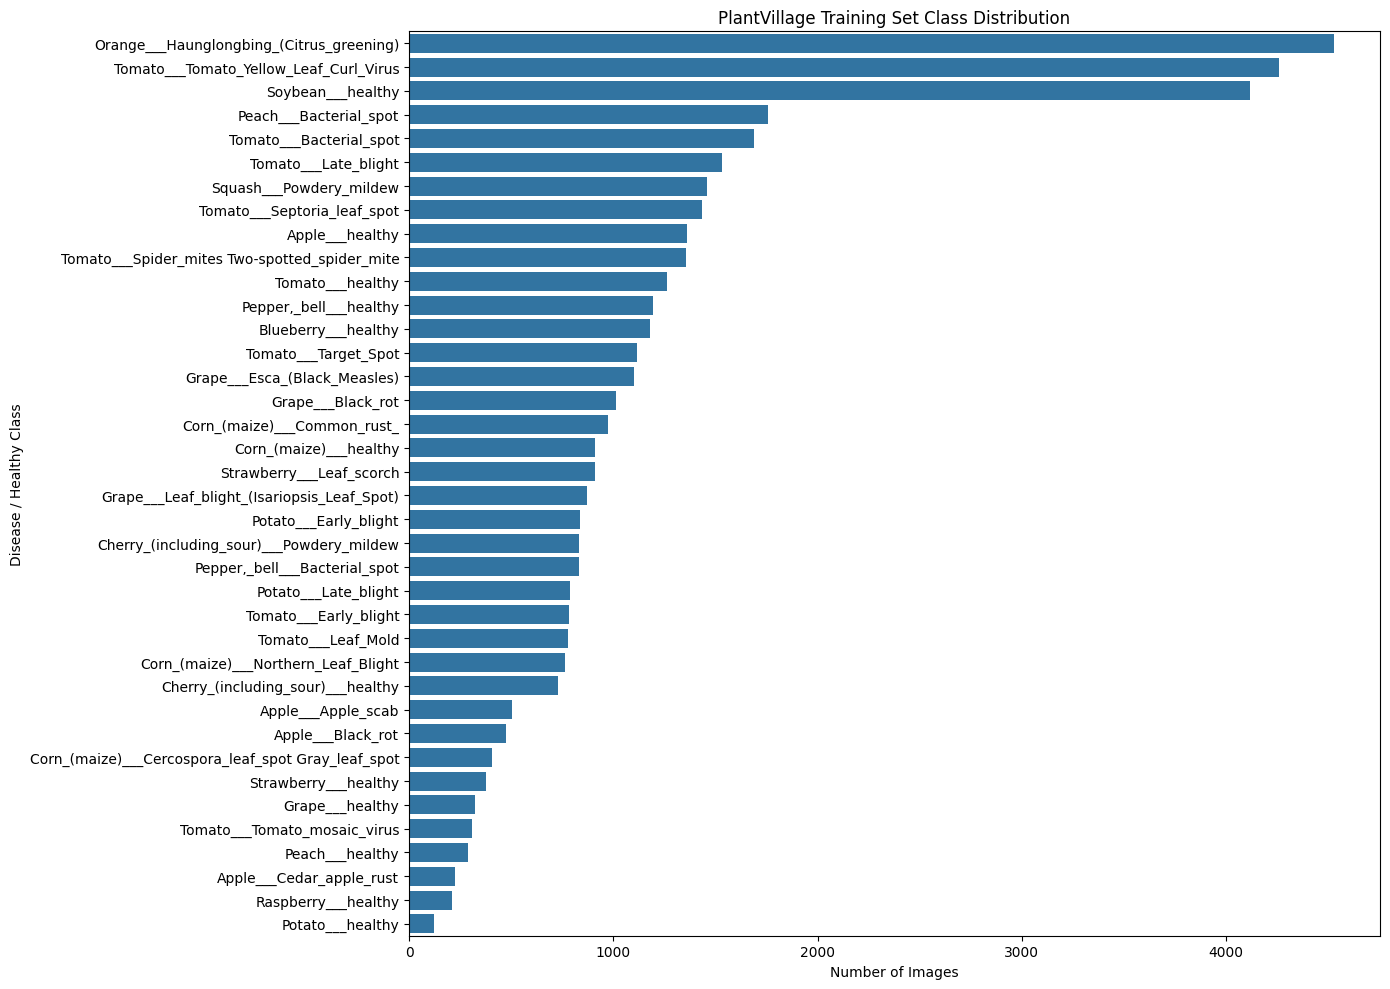

In [ ]:
# Prepare training class distribution for visualization

train_distribution = (
    pd.Series(train_class_counts)
    .sort_values(ascending=False)
)

print("Number of classes:", len(train_distribution))
print("Total training images:", train_distribution.sum())

plt.figure(figsize=(14, 10))

sns.barplot(
    x=train_distribution.values,
    y=train_distribution.index
)

plt.title("PlantVillage Training Set Class Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Disease / Healthy Class")
plt.tight_layout()
plt.show()

##Quantify Class Imbalance

In [ ]:
# Detailed class imbalance analysis

class_stats = pd.DataFrame({
    "class": train_distribution.index,
    "train_images": train_distribution.values
})

class_stats["percentage"] = (
    class_stats["train_images"] /
    class_stats["train_images"].sum() * 100
)

print("=== CLASS IMBALANCE SUMMARY ===")
print("Largest class:")
print(class_stats.loc[class_stats["train_images"].idxmax()])

print("\nSmallest class:")
print(class_stats.loc[class_stats["train_images"].idxmin()])

imbalance_ratio = (
    class_stats["train_images"].max() /
    class_stats["train_images"].min()
)

print("\nImbalance ratio (largest / smallest):",
      round(imbalance_ratio, 2))

print("\nComplete class statistics:")
display(class_stats)

=== CLASS IMBALANCE SUMMARY ===
Largest class:
class           Orange___Haunglongbing_(Citrus_greening)
train_images                                        4527
percentage                                      10.38398
Name: 0, dtype: object

Smallest class:
class           Potato___healthy
train_images                 120
percentage              0.275255
Name: 37, dtype: object

Imbalance ratio (largest / smallest): 37.73

Complete class statistics:


,class,train_images,percentage
0,Orange___Haunglongbing_(Citrus_greening),4527,10.383980
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,4257,9.764657
2,Soybean___healthy,4117,9.443527
3,Peach___Bacterial_spot,1755,4.025599
4,Tomato___Bacterial_spot,1691,3.878796
5,Tomato___Late_blight,1534,3.518671
6,Squash___Powdery_mildew,1457,3.342050
7,Tomato___Septoria_leaf_spot,1434,3.289293
8,Apple___healthy,1359,3.117258
9,Tomato___Spider_mites Two-spotted_spider_mite,1356,3.110377


##Visual Sample Inspection

In [ ]:
# Randomly visualize sample images from different classes

import random

NUM_SAMPLES = 12

sample_entries = random.sample(train_entries, NUM_SAMPLES)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, entry in zip(axes, sample_entries):
    image_path = os.path.join(EXTRACT_DIR, entry)

    image = Image.open(image_path).convert("RGB")

    class_name = entry.split("/")[2]

    ax.imshow(image)
    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.suptitle(
    "Random PlantVillage RGB Training Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

##Analyze Image Dimensions

In [ ]:
# Analyze image dimensions in the training set

from collections import Counter

image_dimensions = Counter()
corrupt_images = []

for entry in train_entries:
    image_path = os.path.join(EXTRACT_DIR, entry)

    try:
        with Image.open(image_path) as img:
            image_dimensions[img.size] += 1
    except Exception as e:
        corrupt_images.append((entry, str(e)))

print("=== IMAGE DIMENSION ANALYSIS ===")
print("Total images checked:", len(train_entries))
print("Unique image dimensions:", len(image_dimensions))
print("Corrupt/unreadable images:", len(corrupt_images))

print("\nMost common image dimensions:")
for dimension, count in image_dimensions.most_common(15):
    percentage = count / len(train_entries) * 100
    print(f"{dimension}: {count} images ({percentage:.2f}%)")

=== IMAGE DIMENSION ANALYSIS ===
Total images checked: 43596
Unique image dimensions: 1
Corrupt/unreadable images: 0

Most common image dimensions:
(256, 256): 43596 images (100.00%)


##Analyze Leaf-Group Structure

In [ ]:
# Analyze the structure of the successfully mapped leaf groups

from collections import Counter, defaultdict

# Count images per leaf group
train_group_sizes = Counter(train_leaf_groups.values())
test_group_sizes = Counter(test_leaf_groups.values())

# Count how many classes are associated with each leaf group
group_classes = defaultdict(set)

for entry, group in train_leaf_groups.items():
    class_name = entry.split("/")[2]
    group_classes[group].add(class_name)

for entry, group in test_leaf_groups.items():
    class_name = entry.split("/")[2]
    group_classes[group].add(class_name)

multi_class_groups = {
    group: classes
    for group, classes in group_classes.items()
    if len(classes) > 1
}

print("=== LEAF-GROUP STRUCTURE ANALYSIS ===")

print("Training leaf groups:", len(train_group_sizes))
print("Test leaf groups:", len(test_group_sizes))

print("\nTraining group-size statistics:")
print("Smallest group:", min(train_group_sizes.values()))
print("Largest group:", max(train_group_sizes.values()))
print("Average group size:", round(np.mean(list(train_group_sizes.values())), 2))
print("Median group size:", round(np.median(list(train_group_sizes.values())), 2))

print("\nGroups containing multiple classes:", len(multi_class_groups))

if multi_class_groups:
    print("\nExample multi-class groups:")
    for group, classes in list(multi_class_groups.items())[:10]:
        print(group, "->", classes)

=== LEAF-GROUP STRUCTURE ANALYSIS ===
Training leaf groups: 6121
Test leaf groups: 1472

Training group-size statistics:
Smallest group: 1
Largest group: 33
Average group size: 5.4
Median group size: 4.0

Groups containing multiple classes: 0


##Analyze Leaf-Mapping Coverage by Class

In [ ]:
# Analyze mapped vs. unmapped images for every training class

mapping_rows = []

for entry in train_entries:
    class_name = entry.split("/")[2]

    if entry in train_leaf_groups:
        mapping_status = "Mapped"
    else:
        mapping_status = "Unmapped"

    mapping_rows.append({
        "class": class_name,
        "mapping_status": mapping_status
    })

mapping_df = pd.DataFrame(mapping_rows)

mapping_summary = (
    mapping_df
    .pivot_table(
        index="class",
        columns="mapping_status",
        values="mapping_status",
        aggfunc="count",
        fill_value=0
    )
)

# Ensure both columns exist
for column in ["Mapped", "Unmapped"]:
    if column not in mapping_summary.columns:
        mapping_summary[column] = 0

mapping_summary["Total"] = (
    mapping_summary["Mapped"] +
    mapping_summary["Unmapped"]
)

mapping_summary["Mapped_%"] = (
    mapping_summary["Mapped"] /
    mapping_summary["Total"] * 100
)

mapping_summary["Unmapped_%"] = (
    mapping_summary["Unmapped"] /
    mapping_summary["Total"] * 100
)

mapping_summary = mapping_summary.sort_values(
    "Unmapped_%",
    ascending=False
)

print("=== LEAF-MAPPING COVERAGE BY CLASS ===")
display(mapping_summary.round(2))

print("\nOverall mapped images:",
      mapping_summary["Mapped"].sum())

print("Overall unmapped images:",
      mapping_summary["Unmapped"].sum())

print(
    "Overall mapping coverage:",
    round(
        mapping_summary["Mapped"].sum() /
        mapping_summary["Total"].sum() * 100,
        2
    ),
    "%"
)

=== LEAF-MAPPING COVERAGE BY CLASS ===


mapping_status,Mapped,Unmapped,Total,Mapped_%,Unmapped_%
class,,,,,
Apple___Apple_scab,0,0,0,NaN,NaN
Apple___Black_rot,0,0,0,NaN,NaN
Apple___Cedar_apple_rust,0,0,0,NaN,NaN
Apple___healthy,0,0,0,NaN,NaN
Blueberry___healthy,0,0,0,NaN,NaN
Cherry_(including_sour)___Powdery_mildew,0,0,0,NaN,NaN
Cherry_(including_sour)___healthy,0,0,0,NaN,NaN
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0,0,0,NaN,NaN
Corn_(maize)___Common_rust_,0,0,0,NaN,NaN



Overall mapped images: 0
Overall unmapped images: 0
Overall mapping coverage: nan %


/tmp/ipykernel_3302/2586361460.py:68: RuntimeWarning: invalid value encountered in scalar divide
  mapping_summary["Mapped"].sum() /


##Correct Leaf-Mapping Coverage by Class

In [ ]:
# Correctly analyze mapped vs. unmapped images by class

mapping_records = []

for entry in train_entries:
    class_name = entry.split("/")[2]

    mapping_records.append({
        "class": class_name,
        "mapped": entry in train_leaf_groups
    })

mapping_df = pd.DataFrame(mapping_records)

# Count total and mapped images per class
coverage_summary = (
    mapping_df
    .groupby("class")
    .agg(
        total_images=("mapped", "size"),
        mapped_images=("mapped", "sum")
    )
)

coverage_summary["unmapped_images"] = (
    coverage_summary["total_images"] -
    coverage_summary["mapped_images"]
)

coverage_summary["mapped_percentage"] = (
    coverage_summary["mapped_images"] /
    coverage_summary["total_images"] * 100
)

coverage_summary["unmapped_percentage"] = (
    coverage_summary["unmapped_images"] /
    coverage_summary["total_images"] * 100
)

coverage_summary = coverage_summary.sort_values(
    "unmapped_percentage",
    ascending=False
)

print("=== CORRECTED LEAF-MAPPING COVERAGE ===")
display(coverage_summary.round(2))

print("\nOverall total images:",
      coverage_summary["total_images"].sum())

print("Overall mapped images:",
      coverage_summary["mapped_images"].sum())

print("Overall unmapped images:",
      coverage_summary["unmapped_images"].sum())

overall_coverage = (
    coverage_summary["mapped_images"].sum() /
    coverage_summary["total_images"].sum() * 100
)

print("Overall mapping coverage:",
      round(overall_coverage, 2), "%")

=== CORRECTED LEAF-MAPPING COVERAGE ===


,total_images,mapped_images,unmapped_images,mapped_percentage,unmapped_percentage
class,,,,,
Tomato___Target_Spot,1116,0,1116,0.00,100.00
Grape___healthy,323,0,323,0.00,100.00
Corn_(maize)___healthy,912,0,912,0.00,100.00
Corn_(maize)___Northern_Leaf_Blight,765,0,765,0.00,100.00
Corn_(maize)___Common_rust_,975,0,975,0.00,100.00
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,406,0,406,0.00,100.00
Tomato___Tomato_mosaic_virus,307,0,307,0.00,100.00
Squash___Powdery_mildew,1457,0,1457,0.00,100.00
Tomato___Late_blight,1534,748,786,48.76,51.24



Overall total images: 43596
Overall mapped images: 33078
Overall unmapped images: 10518
Overall mapping coverage: 75.87 %


##Prepare Group-Aware Stratified Validation Split

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Prepare labels and groups for the training set

train_labels = []
train_groups = []

for entry in train_entries:
    class_name = entry.split("/")[2]
    train_labels.append(class_name)

    # Use the verified leaf group when available.
    # Otherwise, use the image path itself as a unique group.
    if entry in train_leaf_groups:
        group = train_leaf_groups[entry]
    else:
        group = f"UNMAPPED_{entry}"

    train_groups.append(group)

train_labels = np.array(train_labels)
train_groups = np.array(train_groups)

print("Total training images:", len(train_entries))
print("Unique groups:", len(np.unique(train_groups)))
print("Number of classes:", len(np.unique(train_labels)))

# Create a stratified group-aware 10% validation split
sgkf = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=SEED
)

train_idx, val_idx = next(
    sgkf.split(
        np.zeros(len(train_entries)),
        train_labels,
        groups=train_groups
    )
)

print("\nTraining subset:", len(train_idx))
print("Validation subset:", len(val_idx))
print(
    "Validation percentage:",
    round(len(val_idx) / len(train_entries) * 100, 2),
    "%"
)

# Verify that no group occurs in both subsets
train_subset_groups = set(train_groups[train_idx])
val_subset_groups = set(train_groups[val_idx])

shared_groups = train_subset_groups.intersection(val_subset_groups)

print("Shared groups between train and validation:", len(shared_groups))

if len(shared_groups) == 0:
    print("Result: No group leakage detected.")
else:
    print("WARNING: Group leakage detected.")

Total training images: 43596
Unique groups: 16639
Number of classes: 38

Training subset: 39207
Validation subset: 4389
Validation percentage: 10.07 %
Shared groups between train and validation: 0
Result: No group leakage detected.


##Compare Train and Validation Class Distribution

In [ ]:
# Compare class distributions after the group-aware validation split

train_subset_labels = train_labels[train_idx]
val_subset_labels = train_labels[val_idx]

train_subset_counts = Counter(train_subset_labels)
val_subset_counts = Counter(val_subset_labels)

distribution_comparison = pd.DataFrame({
    "class": sorted(train_subset_counts.keys()),
    "train_images": [
        train_subset_counts[c]
        for c in sorted(train_subset_counts.keys())
    ],
    "validation_images": [
        val_subset_counts[c]
        for c in sorted(train_subset_counts.keys())
    ]
})

distribution_comparison["train_%"] = (
    distribution_comparison["train_images"] /
    distribution_comparison["train_images"].sum() * 100
)

distribution_comparison["validation_%"] = (
    distribution_comparison["validation_images"] /
    distribution_comparison["validation_images"].sum() * 100
)

distribution_comparison["percentage_difference"] = (
    distribution_comparison["validation_%"] -
    distribution_comparison["train_%"]
)

print("=== TRAIN vs VALIDATION DISTRIBUTION ===")
display(distribution_comparison.round(3))

print("\nTraining images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Training classes:", len(train_subset_counts))
print("Validation classes:", len(val_subset_counts))

=== TRAIN vs VALIDATION DISTRIBUTION ===


,class,train_images,validation_images,train_%,validation_%,percentage_difference
0,Apple___Apple_scab,460,43,1.173,0.980,-0.194
1,Apple___Black_rot,430,45,1.097,1.025,-0.071
2,Apple___Cedar_apple_rust,203,20,0.518,0.456,-0.062
3,Apple___healthy,1209,150,3.084,3.418,0.334
4,Blueberry___healthy,1069,109,2.727,2.483,-0.243
5,Cherry_(including_sour)___Powdery_mildew,710,123,1.811,2.802,0.992
6,Cherry_(including_sour)___healthy,642,89,1.637,2.028,0.390
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,369,37,0.941,0.843,-0.098
8,Corn_(maize)___Common_rust_,879,96,2.242,2.187,-0.055
9,Corn_(maize)___Northern_Leaf_Blight,687,78,1.752,1.777,0.025



Training images: 39207
Validation images: 4389
Training classes: 38
Validation classes: 38


##Save the Train/Validation Split

In [ ]:
# Save the exact train/validation split for reproducibility

SPLIT_PATH = os.path.join(
    PROJECT_DIR,
    "experiments",
    "train_validation_split.npz"
)

np.savez(
    SPLIT_PATH,
    train_idx=train_idx,
    val_idx=val_idx
)

print("Train/validation split saved successfully.")
print("Path:", SPLIT_PATH)
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Random seed:", SEED)

Train/validation split saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/train_validation_split.npz
Training samples: 39207
Validation samples: 4389
Random seed: 42


##Save Class-to-Index Mapping

In [ ]:
# Create a fixed class-to-index mapping

class_names = sorted(train_class_counts.keys())

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

print("Number of classes:", len(class_names))

print("\nClass-to-index mapping:")
for idx, class_name in idx_to_class.items():
    print(f"{idx}: {class_name}")

Number of classes: 38

Class-to-index mapping:
0: Apple___Apple_scab
1: Apple___Black_rot
2: Apple___Cedar_apple_rust
3: Apple___healthy
4: Blueberry___healthy
5: Cherry_(including_sour)___Powdery_mildew
6: Cherry_(including_sour)___healthy
7: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8: Corn_(maize)___Common_rust_
9: Corn_(maize)___Northern_Leaf_Blight
10: Corn_(maize)___healthy
11: Grape___Black_rot
12: Grape___Esca_(Black_Measles)
13: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14: Grape___healthy
15: Orange___Haunglongbing_(Citrus_greening)
16: Peach___Bacterial_spot
17: Peach___healthy
18: Pepper,_bell___Bacterial_spot
19: Pepper,_bell___healthy
20: Potato___Early_blight
21: Potato___Late_blight
22: Potato___healthy
23: Raspberry___healthy
24: Soybean___healthy
25: Squash___Powdery_mildew
26: Strawberry___Leaf_scorch
27: Strawberry___healthy
28: Tomato___Bacterial_spot
29: Tomato___Early_blight
30: Tomato___Late_blight
31: Tomato___Leaf_Mold
32: Tomato___Septoria_leaf_spot

##Save Class Mapping

In [ ]:
# Save the fixed class mapping for reproducibility

CLASS_MAPPING_PATH = os.path.join(
    PROJECT_DIR,
    "experiments",
    "class_mapping.json"
)

with open(CLASS_MAPPING_PATH, "w") as f:
    json.dump(
        {
            "class_to_idx": class_to_idx,
            "idx_to_class": {str(k): v for k, v in idx_to_class.items()}
        },
        f,
        indent=4
    )

print("Class mapping saved successfully.")
print("Path:", CLASS_MAPPING_PATH)
print("Number of classes:", len(class_to_idx))

Class mapping saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/class_mapping.json
Number of classes: 38


##Create Dataset File Lists and Labels

In [ ]:
# Create structured records for train, validation, and test sets

def create_records(entries):
    records = []

    for entry in entries:
        class_name = entry.split("/")[2]

        records.append({
            "path": os.path.join(EXTRACT_DIR, entry),
            "class_name": class_name,
            "label": class_to_idx[class_name]
        })

    return pd.DataFrame(records)


# Build datasets using the fixed splits
train_records = create_records(
    [train_entries[i] for i in train_idx]
)

val_records = create_records(
    [train_entries[i] for i in val_idx]
)

test_records = create_records(test_entries)


print("=== DATASET RECORDS ===")
print("Training records:", len(train_records))
print("Validation records:", len(val_records))
print("Test records:", len(test_records))

print("\nTraining record example:")
display(train_records.head())

print("\nLabel range:",
      train_records["label"].min(),
      "to",
      train_records["label"].max())

=== DATASET RECORDS ===
Training records: 39207
Validation records: 4389
Test records: 10709

Training record example:


,path,class_name,label
0,/content/drive/MyDrive/Robust_Crop_Disease_Scr...,Raspberry___healthy,23
1,/content/drive/MyDrive/Robust_Crop_Disease_Scr...,Raspberry___healthy,23
2,/content/drive/MyDrive/Robust_Crop_Disease_Scr...,Raspberry___healthy,23
3,/content/drive/MyDrive/Robust_Crop_Disease_Scr...,Raspberry___healthy,23
4,/content/drive/MyDrive/Robust_Crop_Disease_Scr...,Raspberry___healthy,23



Label range: 0 to 37


In [ ]:
# Verify that all dataset record paths exist

def check_paths(records, split_name):
    missing = [
        path for path in records["path"]
        if not os.path.isfile(path)
    ]

    print(f"{split_name}:")
    print(f"  Total records: {len(records)}")
    print(f"  Missing files: {len(missing)}")

    return missing


missing_train_records = check_paths(train_records, "Training")
missing_val_records = check_paths(val_records, "Validation")
missing_test_records = check_paths(test_records, "Test")

total_missing = (
    len(missing_train_records) +
    len(missing_val_records) +
    len(missing_test_records)
)

print("\nTotal missing files:", total_missing)

if total_missing == 0:
    print("Result: All dataset record paths are valid.")
else:
    print("WARNING: Missing dataset files detected.")

Training:
  Total records: 39207
  Missing files: 0
Validation:
  Total records: 4389
  Missing files: 0
Test:
  Total records: 10709
  Missing files: 0

Total missing files: 0
Result: All dataset record paths are valid.


##Define PlantVillage PyTorch Dataset

In [ ]:
class PlantVillageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["path"]
        label = int(row["label"])

        # Load image
        image = Image.open(image_path).convert("RGB")

        # Apply transformations
        if self.transform is not None:
            image = self.transform(image)

        return image, label


print("PlantVillageDataset class defined successfully.")

PlantVillageDataset class defined successfully.


##Check Pretrained Model Normalization

In [ ]:
# Standard ImageNet normalization used by torchvision pretrained models

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

print("ImageNet mean:", IMAGENET_MEAN)
print("ImageNet std :", IMAGENET_STD)

ImageNet mean: [0.485, 0.456, 0.406]
ImageNet std : [0.229, 0.224, 0.225]


##Define Image Transforms

In [ ]:
# Image preprocessing and augmentation

IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Image transforms defined successfully.")
print("Image size:", IMAGE_SIZE)
print("Training augmentation: enabled")
print("Validation/Test augmentation: disabled")

Image transforms defined successfully.
Image size: 224
Training augmentation: enabled
Validation/Test augmentation: disabled


##Create Train, Validation, and Test Dataset Objects

In [ ]:
# Create PyTorch Dataset objects

train_dataset = PlantVillageDataset(
    train_records,
    transform=train_transform
)

val_dataset = PlantVillageDataset(
    val_records,
    transform=eval_transform
)

test_dataset = PlantVillageDataset(
    test_records,
    transform=eval_transform
)

print("Dataset objects created successfully.")

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Dataset objects created successfully.
Training dataset: 39207
Validation dataset: 4389
Test dataset: 10709


##Verify a Transformed Sample

In [ ]:
# Inspect one transformed training sample

sample_image, sample_label = train_dataset[0]

print("Tensor shape:", sample_image.shape)
print("Tensor dtype:", sample_image.dtype)
print("Label:", sample_label)
print("Class:", idx_to_class[sample_label])

print("\nTensor value range:")
print("Minimum:", sample_image.min().item())
print("Maximum:", sample_image.max().item())
print("Mean:", sample_image.mean().item())
print("Standard deviation:", sample_image.std().item())

Tensor shape: torch.Size([3, 224, 224])
Tensor dtype: torch.float32
Label: 23
Class: Raspberry___healthy

Tensor value range:
Minimum: -1.9466564655303955
Maximum: 1.8208280801773071
Mean: -0.24996793270111084
Standard deviation: 0.9326135516166687


##Create DataLoaders

In [ ]:
# Create PyTorch DataLoaders

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully.")

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully.
Batch size: 32
Training batches: 1226
Validation batches: 138
Test batches: 335


##Verify GPU Batch Loading

In [ ]:
# Verify one complete batch on the GPU

images, labels = next(iter(train_loader))

images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

print("=== GPU BATCH CHECK ===")
print("Image batch shape:", images.shape)
print("Image dtype:", images.dtype)
print("Label batch shape:", labels.shape)
print("Label dtype:", labels.dtype)
print("Device:", images.device)

print("\nGPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 3),
      "GB")

print("GPU memory reserved:",
      round(torch.cuda.memory_reserved() / 1024**3, 3),
      "GB")

=== GPU BATCH CHECK ===
Image batch shape: torch.Size([32, 3, 224, 224])
Image dtype: torch.float32
Label batch shape: torch.Size([32])
Label dtype: torch.int64
Device: cuda:0

GPU memory allocated: 0.018 GB
GPU memory reserved: 0.021 GB


##Calculate Class Weights

In [ ]:
# Calculate class weights for handling training-set imbalance

train_label_counts = np.bincount(
    train_records["label"].values,
    minlength=len(class_names)
)

class_weights = (
    len(train_records) /
    (len(class_names) * train_label_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)

print("=== CLASS WEIGHTS ===")
print("Number of classes:", len(class_weights))
print("Minimum weight:", round(class_weights.min().item(), 4))
print("Maximum weight:", round(class_weights.max().item(), 4))

print("\nClass weights:")
for idx, weight in enumerate(class_weights):
    print(
        f"{idx:2d} | "
        f"{idx_to_class[idx]} | "
        f"{weight.item():.4f}"
    )

=== CLASS WEIGHTS ===
Number of classes: 38
Minimum weight: 0.2536
Maximum weight: 9.5534

Class weights:
 0 | Apple___Apple_scab | 2.2430
 1 | Apple___Black_rot | 2.3994
 2 | Apple___Cedar_apple_rust | 5.0826
 3 | Apple___healthy | 0.8534
 4 | Blueberry___healthy | 0.9652
 5 | Cherry_(including_sour)___Powdery_mildew | 1.4532
 6 | Cherry_(including_sour)___healthy | 1.6071
 7 | Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | 2.7961
 8 | Corn_(maize)___Common_rust_ | 1.1738
 9 | Corn_(maize)___Northern_Leaf_Blight | 1.5018
10 | Corn_(maize)___healthy | 1.2567
11 | Grape___Black_rot | 1.1264
12 | Grape___Esca_(Black_Measles) | 1.0454
13 | Grape___Leaf_blight_(Isariopsis_Leaf_Spot) | 1.3093
14 | Grape___healthy | 3.5094
15 | Orange___Haunglongbing_(Citrus_greening) | 0.2536
16 | Peach___Bacterial_spot | 0.6534
17 | Peach___healthy | 4.2459
18 | Pepper,_bell___Bacterial_spot | 1.3648
19 | Pepper,_bell___healthy | 0.9346
20 | Potato___Early_blight | 1.3794
21 | Potato___Late_blight | 

##Define Model Configuration

In [ ]:
# Model configuration

NUM_CLASSES = len(class_names)
MODEL_NAME = "EfficientNetV2-S"

print("=== MODEL CONFIGURATION ===")
print("Model:", MODEL_NAME)
print("Number of classes:", NUM_CLASSES)
print("Input size:", IMAGE_SIZE)
print("Device:", device)

=== MODEL CONFIGURATION ===
Model: EfficientNetV2-S
Number of classes: 38
Input size: 224
Device: cuda


##Load Pretrained EfficientNetV2-S

In [ ]:
# Load pretrained EfficientNetV2-S

from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights

weights = EfficientNet_V2_S_Weights.DEFAULT

model = efficientnet_v2_s(weights=weights)

print("Pretrained EfficientNetV2-S loaded successfully.")
print("Number of parameters:",
      sum(p.numel() for p in model.parameters()))

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:01<00:00, 58.6MB/s]


Pretrained EfficientNetV2-S loaded successfully.
Number of parameters: 21458488
Trainable parameters: 21458488


##Replace Classification Head

In [ ]:
# Replace EfficientNetV2-S classification head for 38 PlantVillage classes

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    NUM_CLASSES
)

print("Classification head replaced successfully.")
print("Input features:", in_features)
print("Output classes:", NUM_CLASSES)
print("New classifier:", model.classifier)

Classification head replaced successfully.
Input features: 1280
Output classes: 38
New classifier: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=38, bias=True)
)


In [ ]:
# Freeze the pretrained EfficientNetV2-S backbone

for param in model.features.parameters():
    param.requires_grad = False

model = model.to(device)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("=== MODEL FREEZING ===")
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)
print("Model device:", next(model.parameters()).device)

=== MODEL FREEZING ===
Total parameters: 20226166
Trainable parameters: 48678
Frozen parameters: 20177488
Model device: cuda:0


##Define Baseline Loss and Optimizer

In [ ]:
# Baseline loss and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("=== BASELINE TRAINING CONFIGURATION ===")
print("Loss:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 1e-3)
print("Weight decay:", 1e-4)
print("Trainable module: classifier only")

=== BASELINE TRAINING CONFIGURATION ===
Loss: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001
Trainable module: classifier only


##Define Training and Validation Functions

In [ ]:
# Training and validation utilities

from sklearn.metrics import accuracy_score, f1_score


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_macro_f1


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_macro_f1


print("Training and validation functions defined successfully.")

Training and validation functions defined successfully.


##Define Checkpoint and Training Configuration

In [ ]:
# Checkpoint and training configuration

EXPERIMENT_DIR = os.path.join(
    PROJECT_DIR,
    "experiments",
    "efficientnetv2s_baseline"
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

BEST_CHECKPOINT_PATH = os.path.join(
    EXPERIMENT_DIR,
    "best_model.pth"
)

LATEST_CHECKPOINT_PATH = os.path.join(
    EXPERIMENT_DIR,
    "latest_checkpoint.pth"
)

HISTORY_PATH = os.path.join(
    EXPERIMENT_DIR,
    "training_history.json"
)

NUM_EPOCHS = 5
EARLY_STOPPING_PATIENCE = 2

best_val_macro_f1 = -1.0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_macro_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

print("=== TRAINING CONFIGURATION ===")
print("Epochs:", NUM_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Monitoring metric: Validation Macro F1")

print("\nExperiment directory:")
print(EXPERIMENT_DIR)

print("\nBest checkpoint:")
print(BEST_CHECKPOINT_PATH)

print("\nLatest checkpoint:")
print(LATEST_CHECKPOINT_PATH)

=== TRAINING CONFIGURATION ===
Epochs: 5
Early stopping patience: 2
Monitoring metric: Validation Macro F1

Experiment directory:
/content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_baseline

Best checkpoint:
/content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_baseline/best_model.pth

Latest checkpoint:
/content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_baseline/latest_checkpoint.pth


##Baseline Training Loop

In [ ]:
# Baseline training loop with checkpointing

import time

start_epoch = 0
patience_counter = 0

print("=== STARTING BASELINE TRAINING ===")

for epoch in range(start_epoch, NUM_EPOCHS):

    epoch_start = time.time()

    train_loss, train_acc, train_f1 = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc, val_f1 = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    # Store metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["train_macro_f1"].append(train_f1)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    history["val_macro_f1"].append(val_f1)

    epoch_time = time.time() - epoch_start

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    print(f"Time: {epoch_time / 60:.2f} min")
    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train Macro F1: {train_f1:.4f}"
    )
    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

    # Check whether this is the best model
    is_best = val_f1 > best_val_macro_f1

    if is_best:
        best_val_macro_f1 = val_f1
        patience_counter = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_macro_f1": best_val_macro_f1,
                "history": history,
                "class_to_idx": class_to_idx,
                "model_name": MODEL_NAME
            },
            BEST_CHECKPOINT_PATH
        )

        print("Best model checkpoint saved.")

    else:
        patience_counter += 1
        print(
            f"No Macro F1 improvement. "
            f"Patience: {patience_counter}/{EARLY_STOPPING_PATIENCE}"
        )

    # Save latest checkpoint after every epoch
    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_macro_f1": best_val_macro_f1,
            "history": history,
            "class_to_idx": class_to_idx,
            "model_name": MODEL_NAME
        },
        LATEST_CHECKPOINT_PATH
    )

    # Save history separately
    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=4)

    print("Latest checkpoint saved.")

    # Early stopping
    if patience_counter >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\n=== BASELINE TRAINING FINISHED ===")
print("Best validation Macro F1:", round(best_val_macro_f1, 4))

=== STARTING BASELINE TRAINING ===

Epoch 1/5
Time: 7.80 min
Train Loss: 0.9341 | Train Acc: 0.7777 | Train Macro F1: 0.7243
Val Loss: 0.5484 | Val Acc: 0.8665 | Val Macro F1: 0.8310
Best model checkpoint saved.
Latest checkpoint saved.

Epoch 2/5
Time: 7.37 min
Train Loss: 0.4886 | Train Acc: 0.8601 | Train Macro F1: 0.8319
Val Loss: 0.4313 | Val Acc: 0.8900 | Val Macro F1: 0.8592
Best model checkpoint saved.
Latest checkpoint saved.

Epoch 3/5
Time: 7.60 min
Train Loss: 0.4307 | Train Acc: 0.8709 | Train Macro F1: 0.8452
Val Loss: 0.3686 | Val Acc: 0.8979 | Val Macro F1: 0.8729
Best model checkpoint saved.
Latest checkpoint saved.

Epoch 4/5
Time: 7.48 min
Train Loss: 0.4046 | Train Acc: 0.8743 | Train Macro F1: 0.8503
Val Loss: 0.3303 | Val Acc: 0.9025 | Val Macro F1: 0.8827
Best model checkpoint saved.
Latest checkpoint saved.

Epoch 5/5
Time: 7.19 min
Train Loss: 0.3900 | Train Acc: 0.8790 | Train Macro F1: 0.8555
Val Loss: 0.3200 | Val Acc: 0.9059 | Val Macro F1: 0.8860
Best mode

##Evaluate Best Baseline on Official Test Set

In [ ]:
# Load the best baseline checkpoint and evaluate on the untouched official test set

checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)

best_epoch = checkpoint["epoch"]
saved_best_f1 = checkpoint["best_val_macro_f1"]

test_loss, test_accuracy, test_macro_f1 = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print("=== OFFICIAL TEST EVALUATION — BASELINE ===")
print("Best checkpoint epoch:", best_epoch)
print("Best validation Macro F1:", round(saved_best_f1, 4))

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Accuracy (%):", round(test_accuracy * 100, 2))
print("Test Macro F1:", round(test_macro_f1, 4))
print("Test Macro F1 (%):", round(test_macro_f1 * 100, 2))

=== OFFICIAL TEST EVALUATION — BASELINE ===
Best checkpoint epoch: 5
Best validation Macro F1: 0.886

Test Loss: 0.3402
Test Accuracy: 0.9016
Test Accuracy (%): 90.16
Test Macro F1: 0.88
Test Macro F1 (%): 88.0


##Baseline Classification Report

In [ ]:
# Detailed per-class evaluation on the official test set

from sklearn.metrics import classification_report

@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()

    all_predictions = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )
        all_labels.extend(
            labels.numpy()
        )

    return np.array(all_labels), np.array(all_predictions)


test_labels, test_predictions = get_predictions(
    model,
    test_loader,
    device
)

report = classification_report(
    test_labels,
    test_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("=== BASELINE TEST CLASSIFICATION REPORT ===")
print(report)

=== BASELINE TEST CLASSIFICATION REPORT ===
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9115    0.8110    0.8583       127
                                 Apple___Black_rot     0.9630    0.8904    0.9253       146
                          Apple___Cedar_apple_rust     0.8596    0.9423    0.8991        52
                                   Apple___healthy     0.9225    0.8741    0.8977       286
                               Blueberry___healthy     0.8874    0.9969    0.9390       324
          Cherry_(including_sour)___Powdery_mildew     0.9471    0.8995    0.9227       219
                 Cherry_(including_sour)___healthy     0.8832    0.9837    0.9308       123
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.7831    0.6075    0.6842       107
                       Corn_(maize)___Common_rust_     0.9348    0.9908    0.9620       217
               Corn_(maize)___North

##Baseline Confusion Matrix

In [ ]:
# Analyze class-to-class confusion on the official test set

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=list(range(NUM_CLASSES))
)

print("=== CONFUSION MATRIX ANALYSIS ===")

# Most frequent misclassifications
confusion_errors = []

for true_idx in range(NUM_CLASSES):
    for pred_idx in range(NUM_CLASSES):
        if true_idx != pred_idx and cm[true_idx, pred_idx] > 0:
            confusion_errors.append({
                "true_class": idx_to_class[true_idx],
                "predicted_class": idx_to_class[pred_idx],
                "errors": int(cm[true_idx, pred_idx])
            })

confusion_errors_df = pd.DataFrame(confusion_errors)

confusion_errors_df = confusion_errors_df.sort_values(
    "errors",
    ascending=False
).reset_index(drop=True)

print("\nTop 20 misclassification pairs:")
display(confusion_errors_df.head(20))

print("\nTotal incorrect predictions:",
      int((test_labels != test_predictions).sum()))

print("Total correct predictions:",
      int((test_labels == test_predictions).sum()))

=== CONFUSION MATRIX ANALYSIS ===

Top 20 misclassification pairs:


,true_class,predicted_class,errors
0,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,38
1,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,36
2,Tomato___Bacterial_spot,Tomato___Septoria_leaf_spot,33
3,Tomato___Early_blight,Tomato___Septoria_leaf_spot,23
4,Tomato___Target_Spot,Tomato___healthy,20
5,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,16
6,Grape___Esca_(Black_Measles),Grape___Black_rot,16
7,Tomato___Bacterial_spot,Tomato___Tomato_Yellow_Leaf_Curl_Virus,16
8,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Spider_mites Two-spotted_spider_mite,15
9,Soybean___healthy,Blueberry___healthy,15



Total incorrect predictions: 1054
Total correct predictions: 9655


##Inspect EfficientNetV2-S Feature Blocks

In [ ]:
# Inspect EfficientNetV2-S feature blocks before fine-tuning

print("=== EFFICIENTNETV2-S FEATURE BLOCKS ===")

for idx, block in enumerate(model.features):
    trainable = any(
        param.requires_grad
        for param in block.parameters()
    )

    print(
        f"Block {idx}: "
        f"{block.__class__.__name__:<25} "
        f"Trainable: {trainable}"
    )

=== EFFICIENTNETV2-S FEATURE BLOCKS ===
Block 0: Conv2dNormActivation      Trainable: False
Block 1: Sequential                Trainable: False
Block 2: Sequential                Trainable: False
Block 3: Sequential                Trainable: False
Block 4: Sequential                Trainable: False
Block 5: Sequential                Trainable: False
Block 6: Sequential                Trainable: False
Block 7: Conv2dNormActivation      Trainable: False


##Save Baseline Benchmark

In [ ]:
# Save the official baseline benchmark

BASELINE_RESULTS_PATH = os.path.join(
    EXPERIMENT_DIR,
    "baseline_results.json"
)

baseline_results = {
    "model": MODEL_NAME,
    "best_epoch": int(best_epoch),
    "validation_macro_f1": float(saved_best_f1),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_correct": int((test_labels == test_predictions).sum()),
    "test_incorrect": int((test_labels != test_predictions).sum())
}

with open(BASELINE_RESULTS_PATH, "w") as f:
    json.dump(baseline_results, f, indent=4)

print("Baseline benchmark saved successfully.")
print("Path:", BASELINE_RESULTS_PATH)

print("\nBaseline Test Accuracy:",
      f"{test_accuracy * 100:.2f}%")

print("Baseline Test Macro F1:",
      f"{test_macro_f1 * 100:.2f}%")

Baseline benchmark saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_baseline/baseline_results.json

Baseline Test Accuracy: 90.16%
Baseline Test Macro F1: 88.00%


##Unfreeze Deeper EfficientNet Blocks

In [ ]:
# Unfreeze deeper EfficientNetV2-S feature blocks for fine-tuning

FINE_TUNE_BLOCKS = [5, 6, 7]

for idx in FINE_TUNE_BLOCKS:
    for param in model.features[idx].parameters():
        param.requires_grad = True

# Keep the classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

print("=== FINE-TUNING CONFIGURATION ===")
print("Unfrozen feature blocks:", FINE_TUNE_BLOCKS)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", frozen_params)

print("\nBlock status:")
for idx, block in enumerate(model.features):
    trainable = any(
        param.requires_grad
        for param in block.parameters()
    )
    print(f"Block {idx}: Trainable = {trainable}")

=== FINE-TUNING CONFIGURATION ===
Unfrozen feature blocks: [5, 6, 7]
Trainable parameters: 18404590
Frozen parameters: 1821576

Block status:
Block 0: Trainable = False
Block 1: Trainable = False
Block 2: Trainable = False
Block 3: Trainable = False
Block 4: Trainable = False
Block 5: Trainable = True
Block 6: Trainable = True
Block 7: Trainable = True


##Configure Fine-Tuning Optimizer

In [ ]:
# Configure optimizer for EfficientNetV2-S fine-tuning

FINE_TUNE_LR = 1e-4
FINE_TUNE_WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=FINE_TUNE_LR,
    weight_decay=FINE_TUNE_WEIGHT_DECAY
)

# Keep the baseline loss for this first fine-tuning experiment
criterion = nn.CrossEntropyLoss()

print("=== FINE-TUNING OPTIMIZER ===")
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", FINE_TUNE_LR)
print("Weight decay:", FINE_TUNE_WEIGHT_DECAY)
print("Loss:", criterion.__class__.__name__)
print("Trainable parameters:", trainable_params)

=== FINE-TUNING OPTIMIZER ===
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Loss: CrossEntropyLoss
Trainable parameters: 18404590


##Initialize Fine-Tuning Experiment

In [ ]:
# Initialize a separate experiment for fine-tuning

FINE_TUNE_DIR = os.path.join(
    PROJECT_DIR,
    "experiments",
    "efficientnetv2s_finetuned"
)

os.makedirs(FINE_TUNE_DIR, exist_ok=True)

FINE_TUNE_BEST_PATH = os.path.join(
    FINE_TUNE_DIR,
    "best_model.pth"
)

FINE_TUNE_LATEST_PATH = os.path.join(
    FINE_TUNE_DIR,
    "latest_checkpoint.pth"
)

FINE_TUNE_HISTORY_PATH = os.path.join(
    FINE_TUNE_DIR,
    "training_history.json"
)

FINE_TUNE_EPOCHS = 5

fine_tune_history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_macro_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

fine_tune_best_val_f1 = -1.0
fine_tune_patience_counter = 0

print("=== FINE-TUNING EXPERIMENT ===")
print("Experiment directory:", FINE_TUNE_DIR)
print("Epochs:", FINE_TUNE_EPOCHS)
print("Best checkpoint:", FINE_TUNE_BEST_PATH)
print("Latest checkpoint:", FINE_TUNE_LATEST_PATH)
print("Monitoring: Validation Macro F1")

=== FINE-TUNING EXPERIMENT ===
Experiment directory: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_finetuned
Epochs: 5
Best checkpoint: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_finetuned/best_model.pth
Latest checkpoint: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_finetuned/latest_checkpoint.pth
Monitoring: Validation Macro F1


##Plot the Final Test Confusion Matrix

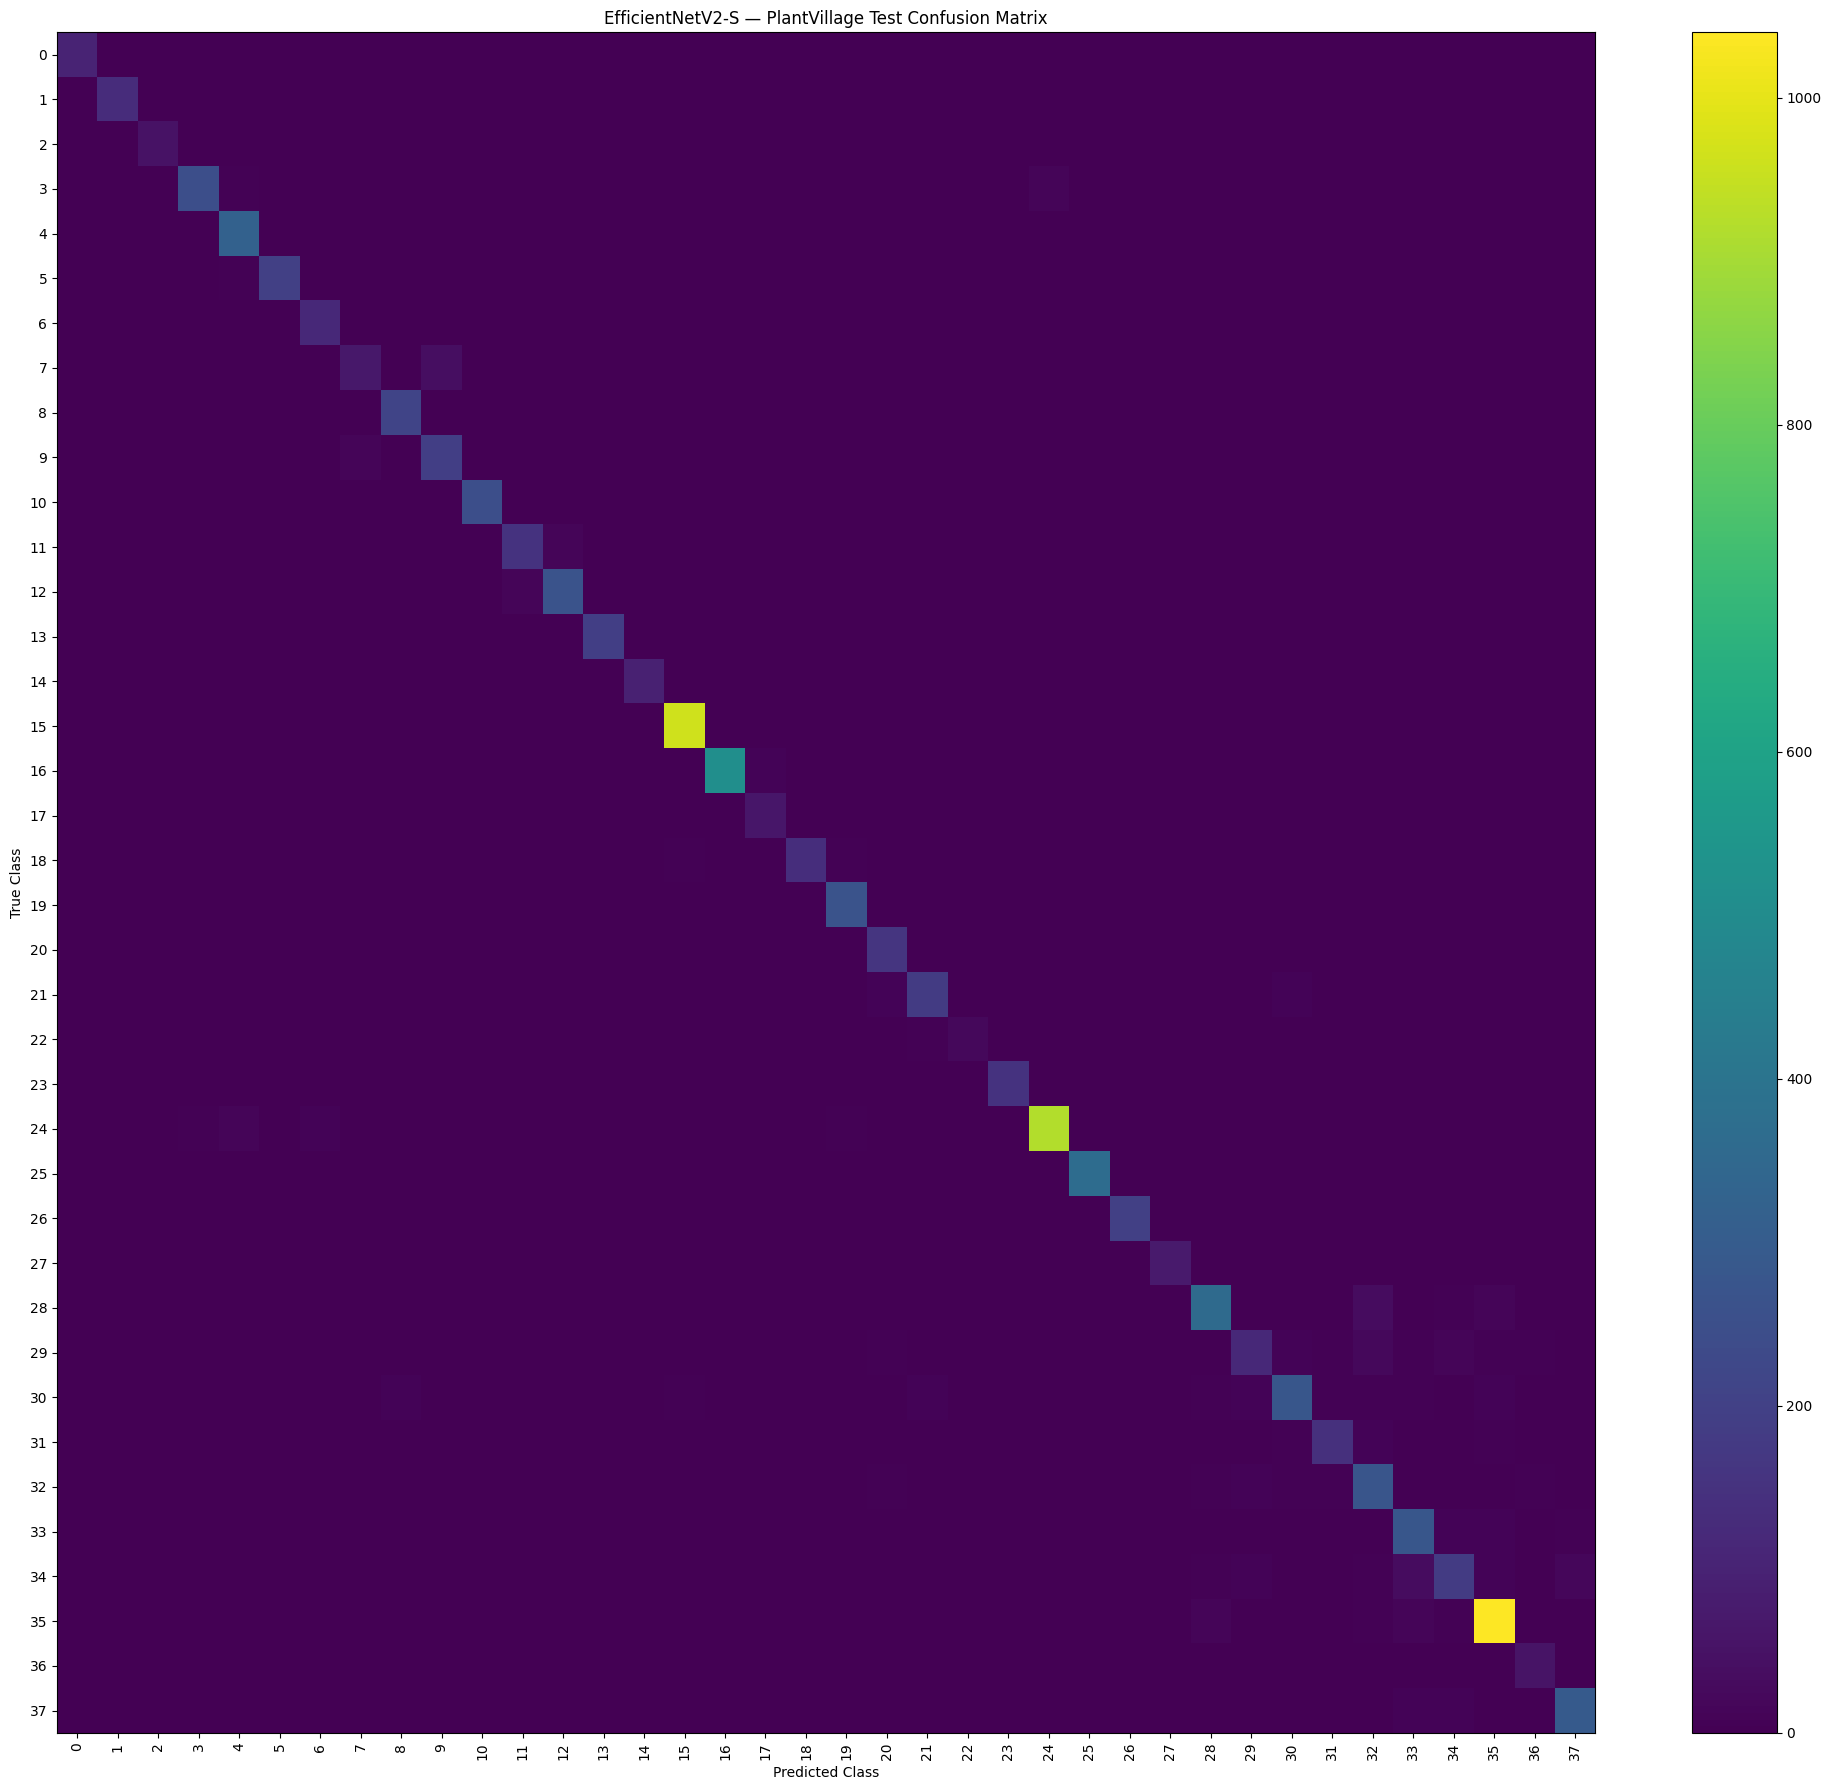

Confusion matrix saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_baseline/final_test_confusion_matrix.png


In [ ]:
# Plot confusion matrix for the final baseline model

plt.figure(figsize=(20, 18))

plt.imshow(cm, interpolation="nearest", aspect="auto")
plt.title("EfficientNetV2-S — PlantVillage Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    range(NUM_CLASSES),
    rotation=90
)

plt.yticks(
    range(NUM_CLASSES),
    range(NUM_CLASSES)
)

plt.tight_layout()

CONFUSION_MATRIX_PATH = os.path.join(
    EXPERIMENT_DIR,
    "final_test_confusion_matrix.png"
)

plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully.")
print("Path:", CONFUSION_MATRIX_PATH)

##Rank Per-Class Test Performance

In [ ]:
# Rank all classes by test F1-score

class_report = classification_report(
    test_labels,
    test_predictions,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_metrics = []

for idx, class_name in enumerate(class_names):
    metrics = class_report[class_name]

    class_metrics.append({
        "class_index": idx,
        "class": class_name,
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1_score": metrics["f1-score"],
        "support": int(metrics["support"])
    })

class_metrics_df = pd.DataFrame(class_metrics)

# Rank from weakest to strongest F1
class_metrics_df = class_metrics_df.sort_values(
    "f1_score",
    ascending=True
).reset_index(drop=True)

print("=== CLASS-WISE TEST PERFORMANCE ===")
display(class_metrics_df)

print("\n=== 10 WEAKEST CLASSES BY F1 ===")
display(class_metrics_df.head(10))

print("\n=== 10 STRONGEST CLASSES BY F1 ===")
display(
    class_metrics_df
    .sort_values("f1_score", ascending=False)
    .head(10)
)

=== CLASS-WISE TEST PERFORMANCE ===


,class_index,class,precision,recall,f1_score,support
0,29,Tomato___Early_blight,0.703488,0.562791,0.625323,215
1,7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,0.783133,0.607477,0.684211,107
2,34,Tomato___Target_Spot,0.765957,0.625000,0.688337,288
3,36,Tomato___Tomato_mosaic_virus,0.674699,0.848485,0.751678,66
4,32,Tomato___Septoria_leaf_spot,0.731383,0.816024,0.771388,337
5,30,Tomato___Late_blight,0.847561,0.741333,0.790896,375
6,33,Tomato___Spider_mites Two-spotted_spider_mite,0.772222,0.868750,0.817647,320
7,22,Potato___healthy,0.923077,0.750000,0.827586,32
8,18,"Pepper,_bell___Bacterial_spot",0.831325,0.831325,0.831325,166
9,17,Peach___healthy,0.797468,0.887324,0.840000,71



=== 10 WEAKEST CLASSES BY F1 ===


,class_index,class,precision,recall,f1_score,support
0,29,Tomato___Early_blight,0.703488,0.562791,0.625323,215
1,7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,0.783133,0.607477,0.684211,107
2,34,Tomato___Target_Spot,0.765957,0.625000,0.688337,288
3,36,Tomato___Tomato_mosaic_virus,0.674699,0.848485,0.751678,66
4,32,Tomato___Septoria_leaf_spot,0.731383,0.816024,0.771388,337
5,30,Tomato___Late_blight,0.847561,0.741333,0.790896,375
6,33,Tomato___Spider_mites Two-spotted_spider_mite,0.772222,0.868750,0.817647,320
7,22,Potato___healthy,0.923077,0.750000,0.827586,32
8,18,"Pepper,_bell___Bacterial_spot",0.831325,0.831325,0.831325,166
9,17,Peach___healthy,0.797468,0.887324,0.840000,71



=== 10 STRONGEST CLASSES BY F1 ===


,class_index,class,precision,recall,f1_score,support
37,10,Corn_(maize)___healthy,0.968992,1.000000,0.984252,250
36,25,Squash___Powdery_mildew,0.994565,0.968254,0.981233,378
35,15,Orange___Haunglongbing_(Citrus_greening),0.966967,0.985714,0.976251,980
34,14,Grape___healthy,0.989583,0.950000,0.969388,100
33,13,Grape___Leaf_blight_(Isariopsis_Leaf_Spot),0.979695,0.946078,0.962594,204
32,23,Raspberry___healthy,0.987013,0.938272,0.962025,162
31,8,Corn_(maize)___Common_rust_,0.934783,0.990783,0.961969,217
30,24,Soybean___healthy,0.973601,0.947585,0.960417,973
29,26,Strawberry___Leaf_scorch,0.916667,0.990000,0.951923,200
28,16,Peach___Bacterial_spot,0.948148,0.944649,0.946396,542


##Save Final Experiment Summary

In [ ]:
# Save final experiment summary for documentation

FINAL_SUMMARY_PATH = os.path.join(
    PROJECT_DIR,
    "experiments",
    "final_experiment_summary.json"
)

final_summary = {
    "dataset": {
        "name": "PlantVillage",
        "representation": "color/RGB",
        "total_images": 54305,
        "training_images": 39207,
        "validation_images": 4389,
        "test_images": 10709,
        "num_classes": 38,
        "train_test_overlap": 0,
        "shared_leaf_groups": 0,
        "image_size": "256x256",
        "model_input_size": "224x224"
    },

    "data_split": {
        "training": 39207,
        "validation": 4389,
        "test": 10709,
        "random_seed": 42,
        "validation_group_leakage": 0
    },

    "model": {
        "architecture": MODEL_NAME,
        "pretrained": "ImageNet",
        "transfer_learning": True,
        "fine_tuning": False,
        "trainable_component": "classification head",
        "num_classes": 38
    },

    "training": {
        "epochs": 5,
        "optimizer": "AdamW",
        "learning_rate": 0.001,
        "weight_decay": 0.0001,
        "loss": "CrossEntropyLoss",
        "batch_size": 32,
        "best_epoch": 5
    },

    "validation": {
        "accuracy": 0.9059,
        "macro_f1": 0.8860,
        "loss": 0.3200
    },

    "official_test": {
        "accuracy": float(test_accuracy),
        "macro_f1": float(test_macro_f1),
        "loss": float(test_loss),
        "correct_predictions": int((test_labels == test_predictions).sum()),
        "incorrect_predictions": int((test_labels != test_predictions).sum())
    },

    "evaluation": {
        "classification_report": "classification_report generated",
        "confusion_matrix": "final_test_confusion_matrix.png"
    }
}

with open(FINAL_SUMMARY_PATH, "w") as f:
    json.dump(final_summary, f, indent=4)

print("=== FINAL EXPERIMENT SUMMARY ===")
print("Summary saved successfully.")
print("Path:", FINAL_SUMMARY_PATH)

print("\nFinal Test Accuracy:",
      f"{test_accuracy * 100:.2f}%")

print("Final Test Macro F1:",
      f"{test_macro_f1 * 100:.2f}%")

=== FINAL EXPERIMENT SUMMARY ===
Summary saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/final_experiment_summary.json

Final Test Accuracy: 90.16%
Final Test Macro F1: 88.00%


##Plot Training and Validation Curves

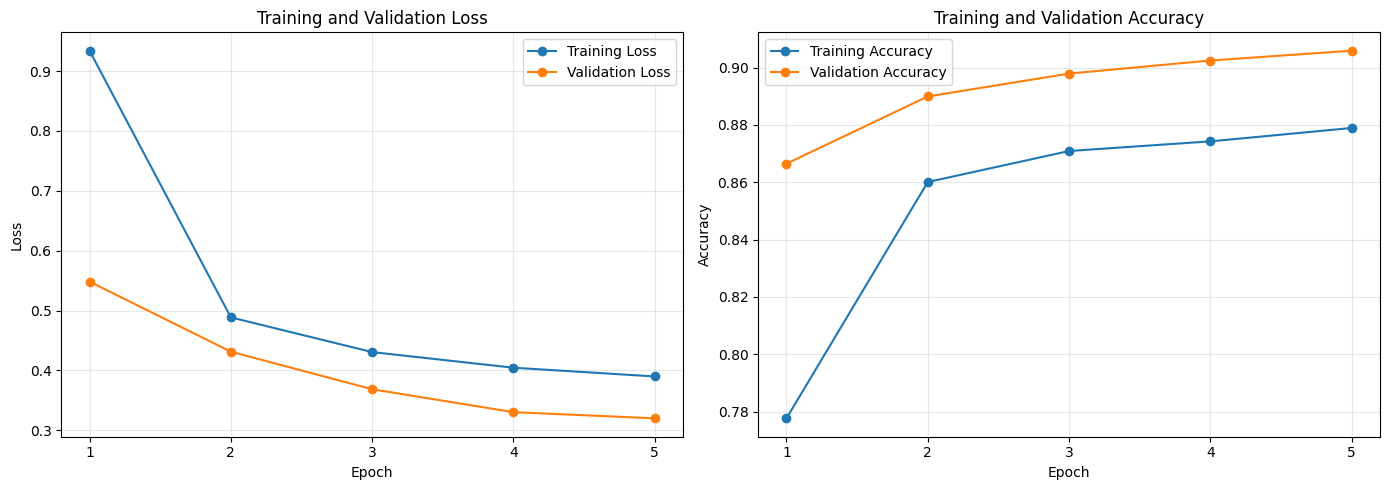

Training/validation curves saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_baseline/training_validation_curves.png


In [ ]:
# Plot final model training and validation curves

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(list(epochs))
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curve
axes[1].plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

axes[1].plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(list(epochs))
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

CURVES_PATH = os.path.join(
    EXPERIMENT_DIR,
    "training_validation_curves.png"
)

plt.savefig(
    CURVES_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training/validation curves saved successfully.")
print("Path:", CURVES_PATH)

##Plot Macro F1 Curves

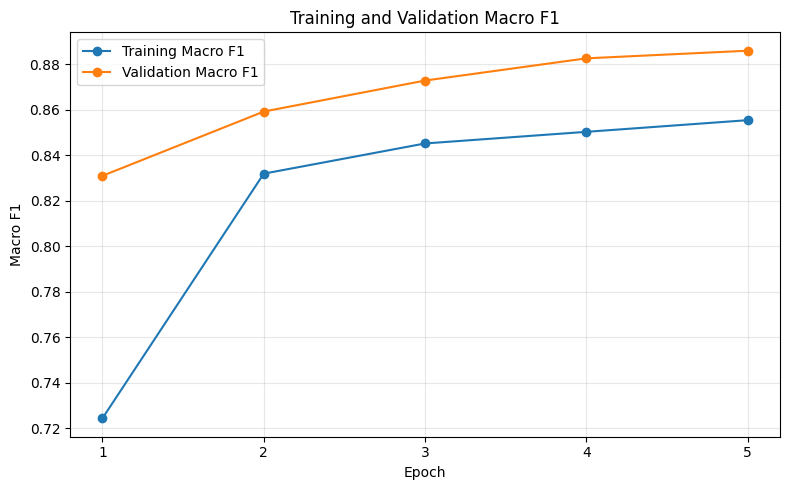

Macro F1 curves saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_baseline/macro_f1_curves.png


In [ ]:
# Plot training and validation Macro F1

epochs = range(1, len(history["train_macro_f1"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_macro_f1"],
    marker="o",
    label="Training Macro F1"
)

plt.plot(
    epochs,
    history["val_macro_f1"],
    marker="o",
    label="Validation Macro F1"
)

plt.title("Training and Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

MACRO_F1_CURVE_PATH = os.path.join(
    EXPERIMENT_DIR,
    "macro_f1_curves.png"
)

plt.savefig(
    MACRO_F1_CURVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Macro F1 curves saved successfully.")
print("Path:", MACRO_F1_CURVE_PATH)

##Save Complete Training History

In [ ]:
# Save complete training history as a CSV table

training_history_df = pd.DataFrame({
    "epoch": range(1, len(history["train_loss"]) + 1),
    "train_loss": history["train_loss"],
    "val_loss": history["val_loss"],
    "train_accuracy": history["train_accuracy"],
    "val_accuracy": history["val_accuracy"],
    "train_macro_f1": history["train_macro_f1"],
    "val_macro_f1": history["val_macro_f1"]
})

TRAINING_HISTORY_CSV = os.path.join(
    EXPERIMENT_DIR,
    "training_history.csv"
)

training_history_df.to_csv(
    TRAINING_HISTORY_CSV,
    index=False
)

print("=== TRAINING HISTORY ===")
display(training_history_df)

print("\nTraining history saved successfully.")
print("Path:", TRAINING_HISTORY_CSV)

=== TRAINING HISTORY ===


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1
0,1,0.934098,0.548361,0.777667,0.866484,0.724296,0.830976
1,2,0.488640,0.431303,0.860102,0.889952,0.831926,0.859240
2,3,0.430664,0.368602,0.870916,0.897927,0.845212,0.872885
3,4,0.404561,0.330288,0.874283,0.902483,0.850326,0.882658
4,5,0.389957,0.319992,0.878950,0.905901,0.855457,0.886009



Training history saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_baseline/training_history.csv


##Save Final Model Artifact

In [ ]:
# Save the final selected model artifact

FINAL_MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "experiments",
    "final_efficientnetv2s_plantvillage.pth"
)

# Load the best baseline checkpoint to guarantee
# that the final artifact is exactly the selected model.
best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

final_model_artifact = {
    "model_state_dict": best_checkpoint["model_state_dict"],
    "model_name": MODEL_NAME,
    "num_classes": NUM_CLASSES,
    "class_to_idx": class_to_idx,
    "input_size": IMAGE_SIZE,
    "pretrained": "ImageNet",
    "fine_tuning": False,
    "best_epoch": best_checkpoint["epoch"],
    "best_validation_macro_f1": best_checkpoint["best_val_macro_f1"],
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1)
}

torch.save(
    final_model_artifact,
    FINAL_MODEL_PATH
)

print("=== FINAL MODEL ARTIFACT ===")
print("Model saved successfully.")
print("Path:", FINAL_MODEL_PATH)
print("Model:", MODEL_NAME)
print("Classes:", NUM_CLASSES)
print("Best epoch:", best_checkpoint["epoch"])
print("Validation Macro F1:",
      f"{best_checkpoint['best_val_macro_f1'] * 100:.2f}%")
print("Official Test Accuracy:",
      f"{test_accuracy * 100:.2f}%")
print("Official Test Macro F1:",
      f"{test_macro_f1 * 100:.2f}%")

=== FINAL MODEL ARTIFACT ===
Model saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/final_efficientnetv2s_plantvillage.pth
Model: EfficientNetV2-S
Classes: 38
Best epoch: 5
Validation Macro F1: 88.60%
Official Test Accuracy: 90.16%
Official Test Macro F1: 88.00%


In [ ]:
# Verify that the final saved model artifact can be reloaded

saved_artifact = torch.load(
    FINAL_MODEL_PATH,
    map_location=device,
    weights_only=False
)

# Reconstruct the model architecture
verified_model = efficientnet_v2_s(weights=None)

verified_model.classifier[1] = nn.Linear(
    verified_model.classifier[1].in_features,
    NUM_CLASSES
)

verified_model.load_state_dict(
    saved_artifact["model_state_dict"]
)

verified_model = verified_model.to(device)
verified_model.eval()

print("=== FINAL MODEL RELOAD VERIFICATION ===")
print("Artifact loaded successfully.")
print("Model:", saved_artifact["model_name"])
print("Number of classes:", saved_artifact["num_classes"])
print("Input size:", saved_artifact["input_size"])
print("Best epoch:", saved_artifact["best_epoch"])
print(
    "Validation Macro F1:",
    f"{saved_artifact['best_validation_macro_f1'] * 100:.2f}%"
)
print(
    "Official Test Accuracy:",
    f"{saved_artifact['test_accuracy'] * 100:.2f}%"
)
print(
    "Official Test Macro F1:",
    f"{saved_artifact['test_macro_f1'] * 100:.2f}%"
)
print(
    "Model device:",
    next(verified_model.parameters()).device
)

=== FINAL MODEL RELOAD VERIFICATION ===
Artifact loaded successfully.
Model: EfficientNetV2-S
Number of classes: 38
Input size: 224
Best epoch: 5
Validation Macro F1: 88.60%
Official Test Accuracy: 90.16%
Official Test Macro F1: 88.00%
Model device: cuda:0


##Prepare Robustness Evaluation Directory

In [ ]:
# ============================================================
# ROBUSTNESS EVALUATION SETUP
# ============================================================

ROBUSTNESS_DIR = os.path.join(
    PROJECT_DIR,
    "experiments",
    "robustness_evaluation"
)

os.makedirs(ROBUSTNESS_DIR, exist_ok=True)

print("=== ROBUSTNESS EVALUATION SETUP ===")
print("Directory created/verified:")
print(ROBUSTNESS_DIR)

print("\nFinal model:")
print(FINAL_MODEL_PATH)

print("\nOfficial clean test baseline:")
print(f"Accuracy : {test_accuracy * 100:.2f}%")
print(f"Macro F1 : {test_macro_f1 * 100:.2f}%")

print("\nOriginal test dataset remains unchanged.")
print("Robustness evaluation will use transformations only during inference.")

=== ROBUSTNESS EVALUATION SETUP ===
Directory created/verified:
/content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation

Final model:
/content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/final_efficientnetv2s_plantvillage.pth

Official clean test baseline:
Accuracy : 90.16%
Macro F1 : 88.00%

Original test dataset remains unchanged.
Robustness evaluation will use transformations only during inference.


##Define Robustness Transformations

In [ ]:
# ============================================================
# ROBUSTNESS TRANSFORMATIONS
# ============================================================

from torchvision import transforms
from PIL import Image, ImageFilter, ImageEnhance
import random


class AddGaussianNoise:
    """
    Add Gaussian noise to a PIL image.
    Severity controls the noise standard deviation.
    """

    def __init__(self, std):
        self.std = std

    def __call__(self, img):
        img_tensor = transforms.ToTensor()(img)

        noise = torch.randn_like(img_tensor) * self.std

        noisy_image = torch.clamp(
            img_tensor + noise,
            0.0,
            1.0
        )

        return transforms.ToPILImage()(noisy_image)


class ReduceBrightness:
    """
    Reduce image brightness.
    Factor < 1.0 makes the image darker.
    """

    def __init__(self, factor):
        self.factor = factor

    def __call__(self, img):
        return ImageEnhance.Brightness(
            img
        ).enhance(self.factor)


class GaussianBlur:
    """
    Apply Gaussian blur.
    """

    def __init__(self, radius):
        self.radius = radius

    def __call__(self, img):
        return img.filter(
            ImageFilter.GaussianBlur(
                radius=self.radius
            )
        )


# ------------------------------------------------------------
# Severity configurations
# ------------------------------------------------------------

ROBUSTNESS_CONFIG = {
    "gaussian_noise": {
        "mild": AddGaussianNoise(std=0.03),
        "moderate": AddGaussianNoise(std=0.07),
        "severe": AddGaussianNoise(std=0.12)
    },

    "brightness": {
        "mild": ReduceBrightness(factor=0.80),
        "moderate": ReduceBrightness(factor=0.60),
        "severe": ReduceBrightness(factor=0.40)
    },

    "gaussian_blur": {
        "mild": GaussianBlur(radius=1.0),
        "moderate": GaussianBlur(radius=2.0),
        "severe": GaussianBlur(radius=3.0)
    }
}


print("=== ROBUSTNESS TRANSFORMATIONS ===")

for corruption, severities in ROBUSTNESS_CONFIG.items():
    print(f"\n{corruption}:")
    for severity in severities:
        print(f"  {severity}")

=== ROBUSTNESS TRANSFORMATIONS ===

gaussian_noise:
  mild
  moderate
  severe

brightness:
  mild
  moderate
  severe

gaussian_blur:
  mild
  moderate
  severe


##Preview Robustness Transformations

In [ ]:
# ============================================================
# ROBUSTNESS TRANSFORMATION VISUAL CHECK
# ============================================================

import matplotlib.pyplot as plt

# Get one original test image directly from the test dataset
sample_image, sample_label = test_dataset[0]

# Recover the original PIL image from the stored test path
sample_path = test_records.iloc[0]["path"]
original_image = Image.open(sample_path).convert("RGB")

preview_conditions = [
    ("Clean", None),
    ("Noise - Mild", ROBUSTNESS_CONFIG["gaussian_noise"]["mild"]),
    ("Noise - Moderate", ROBUSTNESS_CONFIG["gaussian_noise"]["moderate"]),
    ("Noise - Severe", ROBUSTNESS_CONFIG["gaussian_noise"]["severe"]),
    ("Brightness - Mild", ROBUSTNESS_CONFIG["brightness"]["mild"]),
    ("Brightness - Moderate", ROBUSTNESS_CONFIG["brightness"]["moderate"]),
    ("Brightness - Severe", ROBUSTNESS_CONFIG["brightness"]["severe"]),
    ("Blur - Mild", ROBUSTNESS_CONFIG["gaussian_blur"]["mild"]),
    ("Blur - Moderate", ROBUSTNESS_CONFIG["gaussian_blur"]["moderate"]),
    ("Blur - Severe", ROBUSTNESS_CONFIG["gaussian_blur"]["severe"])
]

fig, axes = plt.subplots(
    2, 5,
    figsize=(18, 8)
)

for ax, (title, corruption) in zip(
    axes.ravel(),
    preview_conditions
):
    if corruption is None:
        image = original_image
    else:
        image = corruption(original_image)

    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"Robustness Corruption Preview\nTrue Class: {class_names[sample_label]}",
    fontsize=14
)

plt.tight_layout()

ROBUSTNESS_PREVIEW_PATH = os.path.join(
    ROBUSTNESS_DIR,
    "robustness_transformation_preview.png"
)

plt.savefig(
    ROBUSTNESS_PREVIEW_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=== ROBUSTNESS PREVIEW ===")
print("Sample image:", sample_path)
print("True class:", class_names[sample_label])
print("Preview saved successfully.")
print("Path:", ROBUSTNESS_PREVIEW_PATH)

Output hidden; open in https://colab.research.google.com to view.

##Verify Clean Evaluation Reproducibility

In [ ]:
# ============================================================
# CLEAN TEST REPRODUCIBILITY CHECK
# ============================================================

from sklearn.metrics import accuracy_score, f1_score

verified_model.eval()

clean_predictions = []
clean_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = verified_model(images)
        predictions = torch.argmax(outputs, dim=1)

        clean_predictions.extend(
            predictions.cpu().numpy()
        )

        clean_labels.extend(
            labels.cpu().numpy()
        )

clean_accuracy = accuracy_score(
    clean_labels,
    clean_predictions
)

clean_macro_f1 = f1_score(
    clean_labels,
    clean_predictions,
    average="macro",
    zero_division=0
)

print("=== CLEAN REPRODUCIBILITY CHECK ===")
print(
    "Original Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

print(
    "Reloaded Model Accuracy:",
    f"{clean_accuracy * 100:.2f}%"
)

print(
    "Original Test Macro F1:",
    f"{test_macro_f1 * 100:.2f}%"
)

print(
    "Reloaded Model Macro F1:",
    f"{clean_macro_f1 * 100:.2f}%"
)

print(
    "\nAccuracy difference:",
    f"{abs(test_accuracy - clean_accuracy):.6f}"
)

print(
    "Macro F1 difference:",
    f"{abs(test_macro_f1 - clean_macro_f1):.6f}"
)

if (
    abs(test_accuracy - clean_accuracy) < 1e-6
    and abs(test_macro_f1 - clean_macro_f1) < 1e-6
):
    print("\nRESULT: PASS — exact clean evaluation reproduced.")
else:
    print("\nRESULT: CHECK REQUIRED — evaluation results differ.")

=== CLEAN REPRODUCIBILITY CHECK ===
Original Test Accuracy: 90.16%
Reloaded Model Accuracy: 90.16%
Original Test Macro F1: 88.00%
Reloaded Model Macro F1: 88.00%

Accuracy difference: 0.000000
Macro F1 difference: 0.000000

RESULT: PASS — exact clean evaluation reproduced.


##Build Resumable Robustness Evaluation

In [ ]:
# ============================================================
# RESUMABLE ROBUSTNESS EVALUATION ENGINE
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score


# ------------------------------------------------------------
# Deterministic evaluation preprocessing
# ------------------------------------------------------------

robustness_base_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# Robustness Dataset
# ------------------------------------------------------------

class RobustnessDataset(Dataset):

    def __init__(
        self,
        records,
        corruption=None,
        seed=42
    ):
        self.records = records.reset_index(drop=True)
        self.corruption = corruption
        self.seed = seed

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):

        row = self.records.iloc[idx]

        image = Image.open(
            row["path"]
        ).convert("RGB")

        # Make stochastic noise deterministic
        if self.corruption is not None:
            torch.manual_seed(
                self.seed + idx
            )

            image = self.corruption(image)

        image = robustness_base_transform(image)

        label = int(row["label"])

        return image, label


# ------------------------------------------------------------
# Evaluation function
# ------------------------------------------------------------

def evaluate_robustness_condition(
    model,
    records,
    corruption=None,
    condition_name="clean",
    seed=42,
    batch_size=32
):

    dataset = RobustnessDataset(
        records=records,
        corruption=corruption,
        seed=seed
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    predictions = []
    labels = []

    model.eval()

    with torch.no_grad():

        for images, batch_labels in loader:

            images = images.to(device)

            outputs = model(images)

            batch_predictions = torch.argmax(
                outputs,
                dim=1
            )

            predictions.extend(
                batch_predictions.cpu().numpy()
            )

            labels.extend(
                batch_labels.numpy()
            )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "condition": condition_name,
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1),
        "correct": int(
            np.sum(
                np.array(labels) ==
                np.array(predictions)
            )
        ),
        "incorrect": int(
            np.sum(
                np.array(labels) !=
                np.array(predictions)
            )
        ),
        "total": len(labels)
    }


# ------------------------------------------------------------
# Resumable result storage
# ------------------------------------------------------------

ROBUSTNESS_RESULTS_CSV = os.path.join(
    ROBUSTNESS_DIR,
    "robustness_results.csv"
)

ROBUSTNESS_RESULTS_JSON = os.path.join(
    ROBUSTNESS_DIR,
    "robustness_results.json"
)


def save_robustness_result(result):

    result_df = pd.DataFrame([result])

    if os.path.exists(ROBUSTNESS_RESULTS_CSV):

        existing_df = pd.read_csv(
            ROBUSTNESS_RESULTS_CSV
        )

        existing_df = existing_df[
            existing_df["condition"] != result["condition"]
        ]

        combined_df = pd.concat(
            [existing_df, result_df],
            ignore_index=True
        )

    else:
        combined_df = result_df

    combined_df.to_csv(
        ROBUSTNESS_RESULTS_CSV,
        index=False
    )

    with open(
        ROBUSTNESS_RESULTS_JSON,
        "w"
    ) as f:
        json.dump(
            combined_df.to_dict(orient="records"),
            f,
            indent=4
        )


print("=== ROBUSTNESS EVALUATION ENGINE ===")
print("Dataset class: Ready")
print("Evaluation function: Ready")
print("Checkpointing: Enabled")
print("CSV:", ROBUSTNESS_RESULTS_CSV)
print("JSON:", ROBUSTNESS_RESULTS_JSON)
print("Batch size: 32")
print("Random seed:", 42)

if os.path.exists(ROBUSTNESS_RESULTS_CSV):
    existing = pd.read_csv(
        ROBUSTNESS_RESULTS_CSV
    )
    print(
        "\nExisting completed conditions:",
        len(existing)
    )
else:
    print("\nNo previous robustness results found.")

=== ROBUSTNESS EVALUATION ENGINE ===
Dataset class: Ready
Evaluation function: Ready
Checkpointing: Enabled
CSV: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.csv
JSON: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.json
Batch size: 32
Random seed: 42

No previous robustness results found.


##Gaussian Noise (Mild)

In [ ]:
# ============================================================
# ROBUSTNESS EVALUATION — GAUSSIAN NOISE / MILD
# ============================================================

condition_name = "gaussian_noise_mild"

print("=== ROBUSTNESS CONDITION ===")
print("Condition:", condition_name)
print("Test images:", len(test_records))
print("Severity: Mild")
print("Noise standard deviation: 0.03")

result = evaluate_robustness_condition(
    model=verified_model,
    records=test_records,
    corruption=ROBUSTNESS_CONFIG["gaussian_noise"]["mild"],
    condition_name=condition_name,
    seed=42,
    batch_size=32
)

save_robustness_result(result)

print("\n=== RESULT ===")
print("Condition:", result["condition"])
print("Accuracy:", f"{result['accuracy'] * 100:.2f}%")
print("Macro F1:", f"{result['macro_f1'] * 100:.2f}%")
print("Correct:", result["correct"])
print("Incorrect:", result["incorrect"])
print("Total:", result["total"])

print("\nResult saved successfully.")
print("Path:", ROBUSTNESS_RESULTS_CSV)

=== ROBUSTNESS CONDITION ===
Condition: gaussian_noise_mild
Test images: 10709
Severity: Mild
Noise standard deviation: 0.03

=== RESULT ===
Condition: gaussian_noise_mild
Accuracy: 88.23%
Macro F1: 85.80%
Correct: 9449
Incorrect: 1260
Total: 10709

Result saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.csv


##Gaussian Noise (Moderate)

In [ ]:
# ============================================================
# ROBUSTNESS EVALUATION — GAUSSIAN NOISE / MODERATE
# ============================================================

condition_name = "gaussian_noise_moderate"

print("=== ROBUSTNESS CONDITION ===")
print("Condition:", condition_name)
print("Test images:", len(test_records))
print("Severity: Moderate")
print("Noise standard deviation: 0.07")

result = evaluate_robustness_condition(
    model=verified_model,
    records=test_records,
    corruption=ROBUSTNESS_CONFIG["gaussian_noise"]["moderate"],
    condition_name=condition_name,
    seed=42,
    batch_size=32
)

save_robustness_result(result)

print("\n=== RESULT ===")
print("Condition:", result["condition"])
print("Accuracy:", f"{result['accuracy'] * 100:.2f}%")
print("Macro F1:", f"{result['macro_f1'] * 100:.2f}%")
print("Correct:", result["correct"])
print("Incorrect:", result["incorrect"])
print("Total:", result["total"])

print("\nResult saved successfully.")
print("Path:", ROBUSTNESS_RESULTS_CSV)

=== ROBUSTNESS CONDITION ===
Condition: gaussian_noise_moderate
Test images: 10709
Severity: Moderate
Noise standard deviation: 0.07

=== RESULT ===
Condition: gaussian_noise_moderate
Accuracy: 82.99%
Macro F1: 79.52%
Correct: 8887
Incorrect: 1822
Total: 10709

Result saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.csv


##Gaussian Noise (Severe)

In [ ]:
# ============================================================
# ROBUSTNESS EVALUATION — GAUSSIAN NOISE / SEVERE
# ============================================================

condition_name = "gaussian_noise_severe"

print("=== ROBUSTNESS CONDITION ===")
print("Condition:", condition_name)
print("Test images:", len(test_records))
print("Severity: Severe")
print("Noise standard deviation: 0.12")

result = evaluate_robustness_condition(
    model=verified_model,
    records=test_records,
    corruption=ROBUSTNESS_CONFIG["gaussian_noise"]["severe"],
    condition_name=condition_name,
    seed=42,
    batch_size=32
)

save_robustness_result(result)

print("\n=== RESULT ===")
print("Condition:", result["condition"])
print("Accuracy:", f"{result['accuracy'] * 100:.2f}%")
print("Macro F1:", f"{result['macro_f1'] * 100:.2f}%")
print("Correct:", result["correct"])
print("Incorrect:", result["incorrect"])
print("Total:", result["total"])

print("\nResult saved successfully.")
print("Path:", ROBUSTNESS_RESULTS_CSV)

=== ROBUSTNESS CONDITION ===
Condition: gaussian_noise_severe
Test images: 10709
Severity: Severe
Noise standard deviation: 0.12

=== RESULT ===
Condition: gaussian_noise_severe
Accuracy: 72.43%
Macro F1: 67.82%
Correct: 7756
Incorrect: 2953
Total: 10709

Result saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.csv


##Brightness Reduction (Mild)

In [ ]:
# ============================================================
# ROBUSTNESS EVALUATION — BRIGHTNESS / MILD
# ============================================================

condition_name = "brightness_mild"

print("=== ROBUSTNESS CONDITION ===")
print("Condition:", condition_name)
print("Test images:", len(test_records))
print("Severity: Mild")
print("Brightness factor: 0.80")

result = evaluate_robustness_condition(
    model=verified_model,
    records=test_records,
    corruption=ROBUSTNESS_CONFIG["brightness"]["mild"],
    condition_name=condition_name,
    seed=42,
    batch_size=32
)

save_robustness_result(result)

print("\n=== RESULT ===")
print("Condition:", result["condition"])
print("Accuracy:", f"{result['accuracy'] * 100:.2f}%")
print("Macro F1:", f"{result['macro_f1'] * 100:.2f}%")
print("Correct:", result["correct"])
print("Incorrect:", result["incorrect"])
print("Total:", result["total"])

print("\nResult saved successfully.")
print("Path:", ROBUSTNESS_RESULTS_CSV)

=== ROBUSTNESS CONDITION ===
Condition: brightness_mild
Test images: 10709
Severity: Mild
Brightness factor: 0.80

=== RESULT ===
Condition: brightness_mild
Accuracy: 89.62%
Macro F1: 87.38%
Correct: 9597
Incorrect: 1112
Total: 10709

Result saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.csv


##Brightness Reduction (Moderate)

In [ ]:
# ============================================================
# ROBUSTNESS EVALUATION — BRIGHTNESS / MODERATE
# ============================================================

condition_name = "brightness_moderate"

print("=== ROBUSTNESS CONDITION ===")
print("Condition:", condition_name)
print("Test images:", len(test_records))
print("Severity: Moderate")
print("Brightness factor: 0.60")

result = evaluate_robustness_condition(
    model=verified_model,
    records=test_records,
    corruption=ROBUSTNESS_CONFIG["brightness"]["moderate"],
    condition_name=condition_name,
    seed=42,
    batch_size=32
)

save_robustness_result(result)

print("\n=== RESULT ===")
print("Condition:", result["condition"])
print("Accuracy:", f"{result['accuracy'] * 100:.2f}%")
print("Macro F1:", f"{result['macro_f1'] * 100:.2f}%")
print("Correct:", result["correct"])
print("Incorrect:", result["incorrect"])
print("Total:", result["total"])

print("\nResult saved successfully.")
print("Path:", ROBUSTNESS_RESULTS_CSV)

=== ROBUSTNESS CONDITION ===
Condition: brightness_moderate
Test images: 10709
Severity: Moderate
Brightness factor: 0.60

=== RESULT ===
Condition: brightness_moderate
Accuracy: 88.06%
Macro F1: 85.56%
Correct: 9430
Incorrect: 1279
Total: 10709

Result saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.csv


##Brightness Reduction (Severe)

In [ ]:
# ============================================================
# ROBUSTNESS EVALUATION — BRIGHTNESS / SEVERE
# ============================================================

condition_name = "brightness_severe"

print("=== ROBUSTNESS CONDITION ===")
print("Condition:", condition_name)
print("Test images:", len(test_records))
print("Severity: Severe")
print("Brightness factor: 0.40")

result = evaluate_robustness_condition(
    model=verified_model,
    records=test_records,
    corruption=ROBUSTNESS_CONFIG["brightness"]["severe"],
    condition_name=condition_name,
    seed=42,
    batch_size=32
)

save_robustness_result(result)

print("\n=== RESULT ===")
print("Condition:", result["condition"])
print("Accuracy:", f"{result['accuracy'] * 100:.2f}%")
print("Macro F1:", f"{result['macro_f1'] * 100:.2f}%")
print("Correct:", result["correct"])
print("Incorrect:", result["incorrect"])
print("Total:", result["total"])

print("\nResult saved successfully.")
print("Path:", ROBUSTNESS_RESULTS_CSV)

=== ROBUSTNESS CONDITION ===
Condition: brightness_severe
Test images: 10709
Severity: Severe
Brightness factor: 0.40

=== RESULT ===
Condition: brightness_severe
Accuracy: 83.23%
Macro F1: 79.68%
Correct: 8913
Incorrect: 1796
Total: 10709

Result saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.csv


##Gaussian Blur (Mild)

In [ ]:
# ============================================================
# ROBUSTNESS EVALUATION — GAUSSIAN BLUR / MILD
# ============================================================

condition_name = "gaussian_blur_mild"

print("=== ROBUSTNESS CONDITION ===")
print("Condition:", condition_name)
print("Test images:", len(test_records))
print("Severity: Mild")
print("Blur radius: 1.0")

result = evaluate_robustness_condition(
    model=verified_model,
    records=test_records,
    corruption=ROBUSTNESS_CONFIG["gaussian_blur"]["mild"],
    condition_name=condition_name,
    seed=42,
    batch_size=32
)

save_robustness_result(result)

print("\n=== RESULT ===")
print("Condition:", result["condition"])
print("Accuracy:", f"{result['accuracy'] * 100:.2f}%")
print("Macro F1:", f"{result['macro_f1'] * 100:.2f}%")
print("Correct:", result["correct"])
print("Incorrect:", result["incorrect"])
print("Total:", result["total"])

print("\nResult saved successfully.")
print("Path:", ROBUSTNESS_RESULTS_CSV)

=== ROBUSTNESS CONDITION ===
Condition: gaussian_blur_mild
Test images: 10709
Severity: Mild
Blur radius: 1.0

=== RESULT ===
Condition: gaussian_blur_mild
Accuracy: 80.78%
Macro F1: 77.69%
Correct: 8651
Incorrect: 2058
Total: 10709

Result saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.csv


In [ ]:
# ============================================================
# ROBUSTNESS EVALUATION — GAUSSIAN BLUR / MODERATE
# ============================================================

condition_name = "gaussian_blur_moderate"

print("=== ROBUSTNESS CONDITION ===")
print("Condition:", condition_name)
print("Test images:", len(test_records))
print("Severity: Moderate")
print("Blur radius: 2.0")

result = evaluate_robustness_condition(
    model=verified_model,
    records=test_records,
    corruption=ROBUSTNESS_CONFIG["gaussian_blur"]["moderate"],
    condition_name=condition_name,
    seed=42,
    batch_size=32
)

save_robustness_result(result)

print("\n=== RESULT ===")
print("Condition:", result["condition"])
print("Accuracy:", f"{result['accuracy'] * 100:.2f}%")
print("Macro F1:", f"{result['macro_f1'] * 100:.2f}%")
print("Correct:", result["correct"])
print("Incorrect:", result["incorrect"])
print("Total:", result["total"])

print("\nResult saved successfully.")
print("Path:", ROBUSTNESS_RESULTS_CSV)

=== ROBUSTNESS CONDITION ===
Condition: gaussian_blur_moderate
Test images: 10709
Severity: Moderate
Blur radius: 2.0

=== RESULT ===
Condition: gaussian_blur_moderate
Accuracy: 59.09%
Macro F1: 56.42%
Correct: 6328
Incorrect: 4381
Total: 10709

Result saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.csv


In [ ]:
# ============================================================
# ROBUSTNESS EVALUATION — GAUSSIAN BLUR / SEVERE
# ============================================================

condition_name = "gaussian_blur_severe"

print("=== ROBUSTNESS CONDITION ===")
print("Condition:", condition_name)
print("Test images:", len(test_records))
print("Severity: Severe")
print("Blur radius: 3.0")

result = evaluate_robustness_condition(
    model=verified_model,
    records=test_records,
    corruption=ROBUSTNESS_CONFIG["gaussian_blur"]["severe"],
    condition_name=condition_name,
    seed=42,
    batch_size=32
)

save_robustness_result(result)

print("\n=== RESULT ===")
print("Condition:", result["condition"])
print("Accuracy:", f"{result['accuracy'] * 100:.2f}%")
print("Macro F1:", f"{result['macro_f1'] * 100:.2f}%")
print("Correct:", result["correct"])
print("Incorrect:", result["incorrect"])
print("Total:", result["total"])

print("\nResult saved successfully.")
print("Path:", ROBUSTNESS_RESULTS_CSV)

=== ROBUSTNESS CONDITION ===
Condition: gaussian_blur_severe
Test images: 10709
Severity: Severe
Blur radius: 3.0

=== RESULT ===
Condition: gaussian_blur_severe
Accuracy: 36.38%
Macro F1: 32.07%
Correct: 3896
Incorrect: 6813
Total: 10709

Result saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_results.csv


##Analyze Complete Robustness Results

In [ ]:
# ============================================================
# COMPLETE ROBUSTNESS RESULTS ANALYSIS
# ============================================================

robustness_df = pd.read_csv(
    ROBUSTNESS_RESULTS_CSV
)

# Clean baseline
clean_accuracy = test_accuracy
clean_macro_f1 = test_macro_f1

# Add degradation metrics
robustness_df["accuracy_drop_pp"] = (
    (clean_accuracy - robustness_df["accuracy"]) * 100
)

robustness_df["macro_f1_drop_pp"] = (
    (clean_macro_f1 - robustness_df["macro_f1"]) * 100
)

robustness_df["accuracy_retention_pct"] = (
    robustness_df["accuracy"] /
    clean_accuracy * 100
)

robustness_df["macro_f1_retention_pct"] = (
    robustness_df["macro_f1"] /
    clean_macro_f1 * 100
)

# Identify corruption type and severity
def get_corruption_type(condition):
    return condition.rsplit("_", 1)[0]

def get_severity(condition):
    return condition.rsplit("_", 1)[1]

robustness_df["corruption"] = (
    robustness_df["condition"]
    .apply(get_corruption_type)
)

robustness_df["severity"] = (
    robustness_df["condition"]
    .apply(get_severity)
)

severity_order = {
    "mild": 1,
    "moderate": 2,
    "severe": 3
}

robustness_df["severity_level"] = (
    robustness_df["severity"]
    .map(severity_order)
)

robustness_df = robustness_df.sort_values(
    ["corruption", "severity_level"]
).reset_index(drop=True)

print("=== COMPLETE ROBUSTNESS RESULTS ===")
display(
    robustness_df[
        [
            "condition",
            "corruption",
            "severity",
            "accuracy",
            "macro_f1",
            "accuracy_drop_pp",
            "macro_f1_drop_pp",
            "accuracy_retention_pct",
            "macro_f1_retention_pct"
        ]
    ]
)

print("\n=== CORRUPTION SUMMARY ===")

corruption_summary = (
    robustness_df
    .groupby("corruption")
    .agg(
        mean_accuracy=("accuracy", "mean"),
        mean_macro_f1=("macro_f1", "mean"),
        mean_accuracy_drop_pp=("accuracy_drop_pp", "mean"),
        mean_macro_f1_drop_pp=("macro_f1_drop_pp", "mean"),
        worst_accuracy=("accuracy", "min"),
        worst_macro_f1=("macro_f1", "min")
    )
    .sort_values("mean_accuracy")
)

display(corruption_summary)

# Save analyzed results
ROBUSTNESS_ANALYSIS_CSV = os.path.join(
    ROBUSTNESS_DIR,
    "robustness_analysis.csv"
)

robustness_df.to_csv(
    ROBUSTNESS_ANALYSIS_CSV,
    index=False
)

print("\nAnalyzed robustness results saved successfully.")
print("Path:", ROBUSTNESS_ANALYSIS_CSV)

=== COMPLETE ROBUSTNESS RESULTS ===


,condition,corruption,severity,accuracy,macro_f1,accuracy_drop_pp,macro_f1_drop_pp,accuracy_retention_pct,macro_f1_retention_pct
0,brightness_mild,brightness,mild,0.896162,0.873790,0.541601,0.623232,99.399275,99.291799
1,brightness_moderate,brightness,moderate,0.880568,0.855649,2.101037,2.437334,97.669601,97.230373
2,brightness_severe,brightness,severe,0.832291,0.796782,6.928752,8.324041,92.314863,90.541102
3,gaussian_blur_mild,gaussian_blur,mild,0.807825,0.776924,9.375292,10.309856,89.601243,88.284551
4,gaussian_blur_moderate,gaussian_blur,moderate,0.590905,0.564187,31.067327,31.583555,65.541170,64.110503
5,gaussian_blur_severe,gaussian_blur,severe,0.363806,0.320684,53.777197,55.933813,40.352149,36.440455
6,gaussian_noise_mild,gaussian_noise,mild,0.882342,0.858024,1.923616,2.199842,97.866390,97.500242
7,gaussian_noise_moderate,gaussian_noise,moderate,0.829863,0.795226,7.171538,8.479617,92.045572,90.364315
8,gaussian_noise_severe,gaussian_noise,severe,0.724251,0.678177,17.732748,20.184536,80.331434,77.063607



=== CORRUPTION SUMMARY ===


,mean_accuracy,mean_macro_f1,mean_accuracy_drop_pp,mean_macro_f1_drop_pp,worst_accuracy,worst_macro_f1
corruption,,,,,,
gaussian_blur,0.587512,0.553931,31.406605,32.609075,0.363806,0.320684
gaussian_noise,0.812152,0.777142,8.942634,10.287998,0.724251,0.678177
brightness,0.869673,0.842074,3.190463,3.794869,0.832291,0.796782



Analyzed robustness results saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_analysis.csv


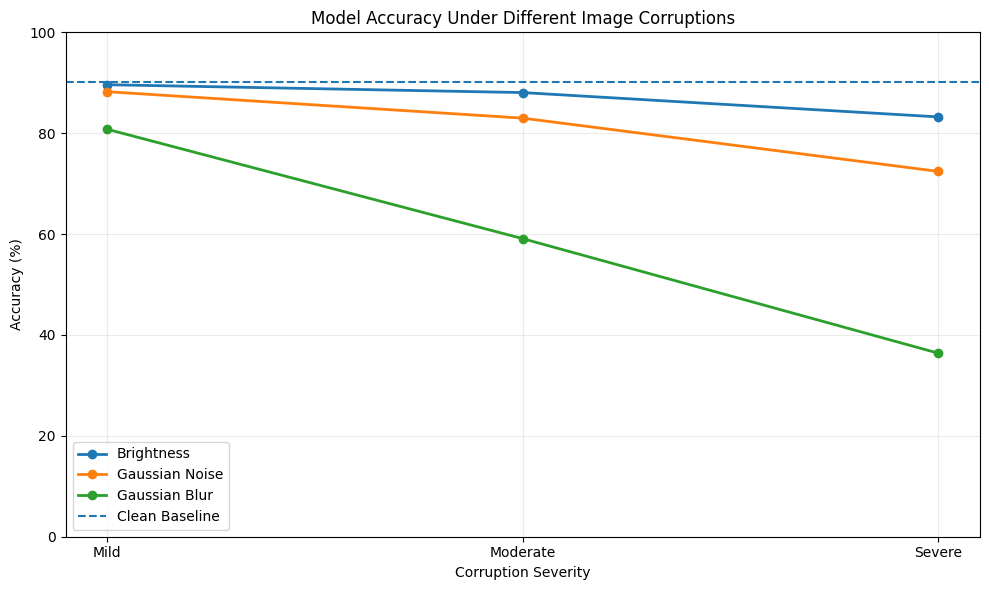

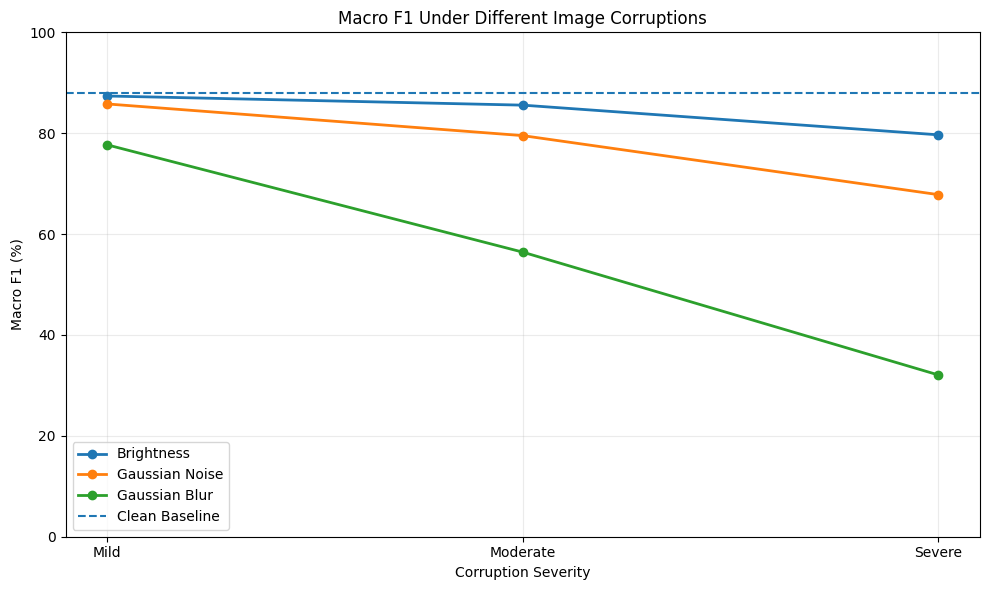

=== ROBUSTNESS FIGURES SAVED ===
Accuracy curve:
/content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_accuracy_curve.png

Macro F1 curve:
/content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/robustness_macro_f1_curve.png


In [ ]:
# ============================================================
# PUBLICATION-QUALITY ROBUSTNESS CURVES
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Plot 1: Accuracy vs Severity
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for corruption in ["brightness", "gaussian_noise", "gaussian_blur"]:

    subset = robustness_df[
        robustness_df["corruption"] == corruption
    ].sort_values("severity_level")

    plt.plot(
        subset["severity_level"],
        subset["accuracy"] * 100,
        marker="o",
        linewidth=2,
        label=corruption.replace("_", " ").title()
    )

plt.axhline(
    clean_accuracy * 100,
    linestyle="--",
    linewidth=1.5,
    label="Clean Baseline"
)

plt.xticks(
    [1, 2, 3],
    ["Mild", "Moderate", "Severe"]
)

plt.xlabel("Corruption Severity")
plt.ylabel("Accuracy (%)")
plt.title(
    "Model Accuracy Under Different Image Corruptions"
)

plt.ylim(0, 100)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

ROBUSTNESS_ACCURACY_FIG = os.path.join(
    ROBUSTNESS_DIR,
    "robustness_accuracy_curve.png"
)

plt.savefig(
    ROBUSTNESS_ACCURACY_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Plot 2: Macro F1 vs Severity
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for corruption in ["brightness", "gaussian_noise", "gaussian_blur"]:

    subset = robustness_df[
        robustness_df["corruption"] == corruption
    ].sort_values("severity_level")

    plt.plot(
        subset["severity_level"],
        subset["macro_f1"] * 100,
        marker="o",
        linewidth=2,
        label=corruption.replace("_", " ").title()
    )

plt.axhline(
    clean_macro_f1 * 100,
    linestyle="--",
    linewidth=1.5,
    label="Clean Baseline"
)

plt.xticks(
    [1, 2, 3],
    ["Mild", "Moderate", "Severe"]
)

plt.xlabel("Corruption Severity")
plt.ylabel("Macro F1 (%)")
plt.title(
    "Macro F1 Under Different Image Corruptions"
)

plt.ylim(0, 100)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

ROBUSTNESS_F1_FIG = os.path.join(
    ROBUSTNESS_DIR,
    "robustness_macro_f1_curve.png"
)

plt.savefig(
    ROBUSTNESS_F1_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("=== ROBUSTNESS FIGURES SAVED ===")
print("Accuracy curve:")
print(ROBUSTNESS_ACCURACY_FIG)

print("\nMacro F1 curve:")
print(ROBUSTNESS_F1_FIG)

In [ ]:
# ============================================================
# FINAL ROBUSTNESS SUMMARY
# ============================================================

import json
import os

# ------------------------------------------------------------
# Build corruption-level summary
# ------------------------------------------------------------

corruption_summary_records = []

for corruption in ["brightness", "gaussian_noise", "gaussian_blur"]:

    subset = robustness_df[
        robustness_df["corruption"] == corruption
    ].sort_values("severity_level")

    corruption_summary_records.append({
        "corruption": corruption,
        "mean_accuracy": float(subset["accuracy"].mean()),
        "mean_macro_f1": float(subset["macro_f1"].mean()),
        "mean_accuracy_drop_pp": float(
            subset["accuracy_drop_pp"].mean()
        ),
        "mean_macro_f1_drop_pp": float(
            subset["macro_f1_drop_pp"].mean()
        ),
        "worst_accuracy": float(
            subset["accuracy"].min()
        ),
        "worst_macro_f1": float(
            subset["macro_f1"].min()
        )
    })


# ------------------------------------------------------------
# Identify most/least damaging corruption
# ------------------------------------------------------------

sorted_by_drop = sorted(
    corruption_summary_records,
    key=lambda x: x["mean_accuracy_drop_pp"],
    reverse=True
)

most_damaging_corruption = sorted_by_drop[0]
least_damaging_corruption = sorted_by_drop[-1]


# ------------------------------------------------------------
# Complete final report
# ------------------------------------------------------------

final_robustness_summary = {

    "experiment": {
        "name": "Controlled Corruption Robustness Evaluation",
        "model": "EfficientNetV2-S",
        "dataset": "PlantVillage RGB",
        "number_of_classes": 38,
        "test_images": int(len(test_records)),
        "random_seed": 42
    },

    "clean_baseline": {
        "accuracy": float(clean_accuracy),
        "accuracy_percent": float(clean_accuracy * 100),
        "macro_f1": float(clean_macro_f1),
        "macro_f1_percent": float(clean_macro_f1 * 100)
    },

    "corruption_results": (
        robustness_df[
            [
                "condition",
                "corruption",
                "severity",
                "accuracy",
                "macro_f1",
                "accuracy_drop_pp",
                "macro_f1_drop_pp",
                "accuracy_retention_pct",
                "macro_f1_retention_pct"
            ]
        ]
        .to_dict(orient="records")
    ),

    "corruption_summary": corruption_summary_records,

    "key_findings": {
        "most_damaging_corruption": (
            most_damaging_corruption["corruption"]
        ),
        "least_damaging_corruption": (
            least_damaging_corruption["corruption"]
        ),
        "largest_mean_accuracy_drop_pp": (
            most_damaging_corruption["mean_accuracy_drop_pp"]
        ),
        "smallest_mean_accuracy_drop_pp": (
            least_damaging_corruption["mean_accuracy_drop_pp"]
        )
    },

    "artifacts": {
        "raw_results_csv": ROBUSTNESS_RESULTS_CSV,
        "raw_results_json": ROBUSTNESS_RESULTS_JSON,
        "analysis_csv": ROBUSTNESS_ANALYSIS_CSV,
        "accuracy_curve": ROBUSTNESS_ACCURACY_FIG,
        "macro_f1_curve": ROBUSTNESS_F1_FIG
    }
}


# ------------------------------------------------------------
# Save final robustness summary
# ------------------------------------------------------------

ROBUSTNESS_FINAL_JSON = os.path.join(
    ROBUSTNESS_DIR,
    "final_robustness_summary.json"
)

with open(
    ROBUSTNESS_FINAL_JSON,
    "w"
) as f:
    json.dump(
        final_robustness_summary,
        f,
        indent=4
    )


# ------------------------------------------------------------
# Display final summary
# ------------------------------------------------------------

print("=== FINAL ROBUSTNESS SUMMARY ===")

print(
    f"Clean Accuracy: "
    f"{clean_accuracy * 100:.2f}%"
)

print(
    f"Clean Macro F1: "
    f"{clean_macro_f1 * 100:.2f}%"
)

print("\nCorruption-level summary:")

for item in corruption_summary_records:

    print(
        f"\n{item['corruption']}"
    )

    print(
        f"  Mean Accuracy: "
        f"{item['mean_accuracy'] * 100:.2f}%"
    )

    print(
        f"  Mean Macro F1: "
        f"{item['mean_macro_f1'] * 100:.2f}%"
    )

    print(
        f"  Mean Accuracy Drop: "
        f"{item['mean_accuracy_drop_pp']:.2f} pp"
    )

    print(
        f"  Worst Accuracy: "
        f"{item['worst_accuracy'] * 100:.2f}%"
    )

print(
    "\nMost damaging corruption:",
    most_damaging_corruption["corruption"]
)

print(
    "Least damaging corruption:",
    least_damaging_corruption["corruption"]
)

print(
    "\nFinal robustness summary saved successfully."
)

print(
    "Path:",
    ROBUSTNESS_FINAL_JSON
)

=== FINAL ROBUSTNESS SUMMARY ===
Clean Accuracy: 90.16%
Clean Macro F1: 88.00%

Corruption-level summary:

brightness
  Mean Accuracy: 86.97%
  Mean Macro F1: 84.21%
  Mean Accuracy Drop: 3.19 pp
  Worst Accuracy: 83.23%

gaussian_noise
  Mean Accuracy: 81.22%
  Mean Macro F1: 77.71%
  Mean Accuracy Drop: 8.94 pp
  Worst Accuracy: 72.43%

gaussian_blur
  Mean Accuracy: 58.75%
  Mean Macro F1: 55.39%
  Mean Accuracy Drop: 31.41 pp
  Worst Accuracy: 36.38%

Most damaging corruption: gaussian_blur
Least damaging corruption: brightness

Final robustness summary saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation/final_robustness_summary.json


##Prepare Grad-CAM

In [ ]:
# ============================================================
# EXPLAINABILITY — GRAD-CAM SETUP
# ============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

EXPLAINABILITY_DIR = os.path.join(
    PROJECT_DIR,
    "experiments",
    "explainability"
)

os.makedirs(EXPLAINABILITY_DIR, exist_ok=True)


# ------------------------------------------------------------
# Grad-CAM implementation
# ------------------------------------------------------------

class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_hook = target_layer.register_forward_hook(
            self._save_activation
        )

        self.backward_hook = target_layer.register_full_backward_hook(
            self._save_gradient
        )

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, image_tensor, target_class):

        self.model.zero_grad()

        output = self.model(image_tensor)

        score = output[:, target_class].sum()

        score.backward()

        # Global average pooling of gradients
        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weighted activation maps
        cam = (
            weights * self.activations
        ).sum(dim=1, keepdim=True)

        cam = F.relu(cam)

        # Resize to input image size
        cam = F.interpolate(
            cam,
            size=image_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Normalize each CAM
        cam = cam.squeeze()

        cam_min = cam.min()
        cam_max = cam.max()

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min + 1e-8
        )

        return output.detach(), cam.cpu().numpy()

    def remove_hooks(self):

        self.forward_hook.remove()
        self.backward_hook.remove()


# ------------------------------------------------------------
# EfficientNetV2-S target layer
# ------------------------------------------------------------

target_layer = verified_model.features[7]

print("=== GRAD-CAM SETUP ===")
print("Model: EfficientNetV2-S")
print("Target layer:")
print(target_layer)

print("\nTarget layer index: features[7]")

print(
    "\nTarget layer trainable:",
    any(
        p.requires_grad
        for p in target_layer.parameters()
    )
)

print(
    "Explainability directory:",
    EXPLAINABILITY_DIR
)

print("\nGrad-CAM engine defined successfully.")

=== GRAD-CAM SETUP ===
Model: EfficientNetV2-S
Target layer:
Conv2dNormActivation(
  (0): Conv2d(256, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)

Target layer index: features[7]

Target layer trainable: True
Explainability directory: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/explainability

Grad-CAM engine defined successfully.


##Find One Correctly Classified Test Image

In [ ]:
# ============================================================
# EXPLAINABILITY — SELECT A CORRECTLY CLASSIFIED TEST IMAGE
# ============================================================

verified_model.eval()

correct_example = None

print("Searching for a correctly classified test image...")

with torch.no_grad():

    for idx in range(len(test_dataset)):

        image, true_label = test_dataset[idx]

        input_tensor = image.unsqueeze(0).to(device)

        output = verified_model(input_tensor)

        predicted_label = output.argmax(dim=1).item()

        if predicted_label == true_label:

            correct_example = {
                "index": idx,
                "image": image,
                "true_label": true_label,
                "predicted_label": predicted_label,
                "confidence": torch.softmax(
                    output,
                    dim=1
                )[0, predicted_label].item()
            }

            break


if correct_example is None:
    raise RuntimeError(
        "No correctly classified test image was found."
    )


print("\n=== CORRECT TEST EXAMPLE FOUND ===")
print("Dataset index:", correct_example["index"])
print(
    "True class:",
    class_names[correct_example["true_label"]]
)
print(
    "Predicted class:",
    class_names[correct_example["predicted_label"]]
)
print(
    "Confidence:",
    f"{correct_example['confidence'] * 100:.2f}%"
)
print(
    "Tensor shape:",
    tuple(correct_example["image"].shape)
)

Searching for a correctly classified test image...

=== CORRECT TEST EXAMPLE FOUND ===
Dataset index: 0
True class: Raspberry___healthy
Predicted class: Raspberry___healthy
Confidence: 99.44%
Tensor shape: (3, 224, 224)


##Generate First Grad-CAM

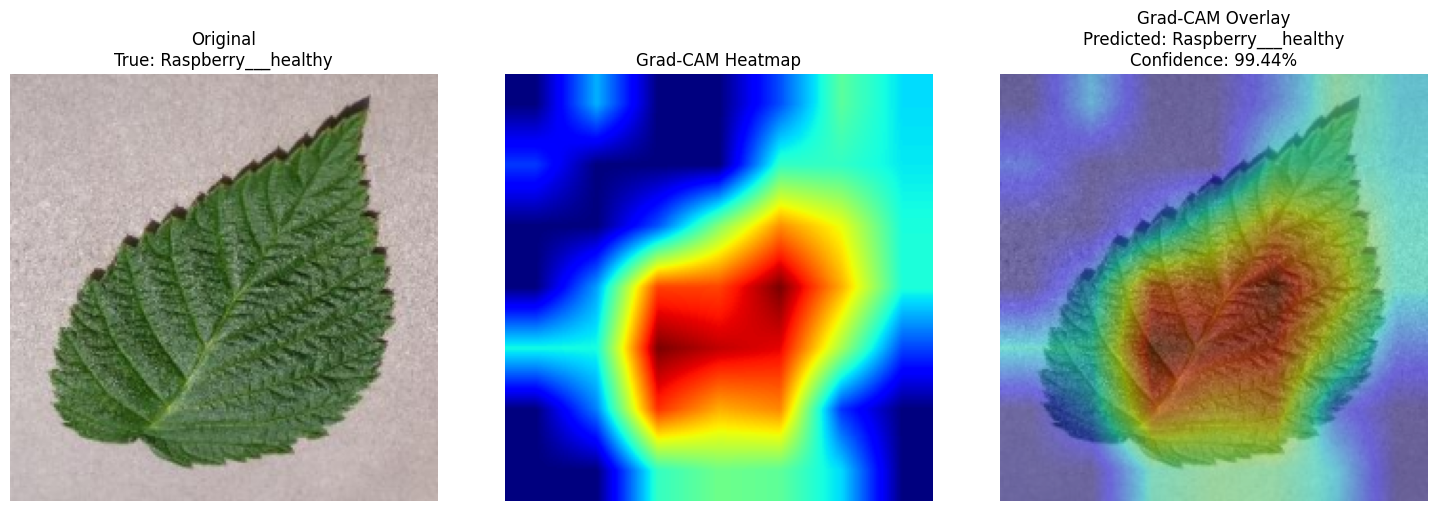

=== GRAD-CAM PREVIEW SAVED ===
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/explainability/gradcam_first_example.png
Target class: Raspberry___healthy
Confidence: 99.44%


In [ ]:
# ============================================================
# EXPLAINABILITY — FIRST GRAD-CAM VISUALIZATION
# ============================================================

verified_model.eval()

# Prepare image
example_image = correct_example["image"]
input_tensor = example_image.unsqueeze(0).to(device)

target_class = correct_example["predicted_label"]

# Create Grad-CAM object
grad_cam = GradCAM(
    model=verified_model,
    target_layer=target_layer
)

# Generate CAM
output, cam = grad_cam.generate(
    image_tensor=input_tensor,
    target_class=target_class
)

# Convert normalized tensor back to displayable image
image_np = example_image.cpu().numpy().transpose(1, 2, 0)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_np = image_np * std + mean
image_np = np.clip(image_np, 0, 1)

# Create visualization
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

# Original
axes[0].imshow(image_np)
axes[0].set_title(
    f"Original\n"
    f"True: {class_names[correct_example['true_label']]}"
)
axes[0].axis("off")

# Grad-CAM heatmap
axes[1].imshow(cam, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis("off")

# Overlay
axes[2].imshow(image_np)
axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.45
)
axes[2].set_title(
    f"Grad-CAM Overlay\n"
    f"Predicted: {class_names[target_class]}\n"
    f"Confidence: {correct_example['confidence'] * 100:.2f}%"
)
axes[2].axis("off")

plt.tight_layout()

GRADCAM_PREVIEW_PATH = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam_first_example.png"
)

plt.savefig(
    GRADCAM_PREVIEW_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=== GRAD-CAM PREVIEW SAVED ===")
print("Path:", GRADCAM_PREVIEW_PATH)
print("Target class:", class_names[target_class])
print(
    "Confidence:",
    f"{correct_example['confidence'] * 100:.2f}%"
)

In [ ]:
# ============================================================
# EXPLAINABILITY — REPRESENTATIVE GRAD-CAM OVERVIEW
# SELF-CONTAINED RECOVERY VERSION
# ============================================================

verified_model.eval()

# ------------------------------------------------------------
# Select correctly classified examples from different classes
# ------------------------------------------------------------

selected_examples = []
selected_classes = set()

MAX_EXAMPLES = 12

print("Selecting representative correctly classified samples...")

for idx in range(len(test_dataset)):

    image, true_label = test_dataset[idx]

    if true_label in selected_classes:
        continue

    input_tensor = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = verified_model(input_tensor)

    predicted_label = output.argmax(dim=1).item()

    if predicted_label == true_label:

        probabilities = torch.softmax(
            output,
            dim=1
        )

        confidence = probabilities[
            0,
            predicted_label
        ].item()

        selected_examples.append({
            "index": idx,
            "image": image,
            "true_label": true_label,
            "predicted_label": predicted_label,
            "confidence": confidence
        })

        selected_classes.add(true_label)

    if len(selected_examples) >= MAX_EXAMPLES:
        break


print(
    "Selected examples:",
    len(selected_examples)
)


# ------------------------------------------------------------
# Create Grad-CAM engine
# ------------------------------------------------------------

grad_cam = GradCAM(
    model=verified_model,
    target_layer=target_layer
)

gradcam_overview = []


# ------------------------------------------------------------
# Generate Grad-CAM for each example
# ------------------------------------------------------------

for example in selected_examples:

    image = example["image"]

    input_tensor = image.unsqueeze(0).to(device)

    target_class = example["predicted_label"]

    output, cam = grad_cam.generate(
        image_tensor=input_tensor,
        target_class=target_class
    )

    # Denormalize
    image_np = (
        image.cpu().numpy()
        .transpose(1, 2, 0)
    )

    mean = np.array(
        [0.485, 0.456, 0.406]
    )

    std = np.array(
        [0.229, 0.224, 0.225]
    )

    image_np = (
        image_np * std + mean
    )

    image_np = np.clip(
        image_np,
        0,
        1
    )

    gradcam_overview.append({
        "image": image_np,
        "cam": cam,
        "class_name": class_names[target_class],
        "confidence": example["confidence"]
    })


grad_cam.remove_hooks()


# ------------------------------------------------------------
# Create overview figure
# ------------------------------------------------------------

n_examples = len(gradcam_overview)

cols = 3
rows = int(np.ceil(n_examples / cols))

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(15, rows * 5)
)

axes = np.array(axes).reshape(-1)

for i, item in enumerate(gradcam_overview):

    axes[i].imshow(item["image"])

    axes[i].imshow(
        item["cam"],
        cmap="jet",
        alpha=0.45
    )

    axes[i].set_title(
        f"{item['class_name']}\n"
        f"Confidence: {item['confidence'] * 100:.1f}%"
    )

    axes[i].axis("off")


# Hide unused axes
for i in range(
    n_examples,
    len(axes)
):
    axes[i].axis("off")


fig.suptitle(
    "Grad-CAM Explanations for Representative Test Samples",
    fontsize=16
)

plt.tight_layout()

GRADCAM_OVERVIEW_PATH = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam_representative_overview.png"
)

plt.savefig(
    GRADCAM_OVERVIEW_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\n=== GRAD-CAM OVERVIEW SAVED ===")
print(
    "Examples:",
    n_examples
)
print(
    "Path:",
    GRADCAM_OVERVIEW_PATH
)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ============================================================
# EXPLAINABILITY — GRAD-CAM FOR MISCLASSIFIED SAMPLES
# ============================================================

verified_model.eval()

misclassified_examples = []

print("Searching for representative misclassified samples...")

# Prefer difficult classes identified from the test report
target_difficult_classes = {
    29,  # Tomato___Early_blight
    7,   # Corn Cercospora
    34,  # Tomato___Target_Spot
    32,  # Tomato___Septoria_leaf_spot
    30,  # Tomato___Late_blight
    33   # Tomato___Spider_mites
}

selected_error_classes = set()

for idx in range(len(test_dataset)):

    image, true_label = test_dataset[idx]

    # Focus first on our identified weak classes
    if true_label not in target_difficult_classes:
        continue

    input_tensor = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = verified_model(input_tensor)

    predicted_label = output.argmax(dim=1).item()

    # Keep only incorrect predictions
    if predicted_label == true_label:
        continue

    probabilities = torch.softmax(
        output,
        dim=1
    )

    confidence = probabilities[
        0,
        predicted_label
    ].item()

    # One representative error per difficult class
    if true_label not in selected_error_classes:

        misclassified_examples.append({
            "index": idx,
            "image": image,
            "true_label": true_label,
            "predicted_label": predicted_label,
            "confidence": confidence
        })

        selected_error_classes.add(true_label)

    if len(misclassified_examples) >= 6:
        break


print("\n=== MISCLASSIFIED EXAMPLES ===")

for i, example in enumerate(misclassified_examples):

    print(
        f"{i + 1}. "
        f"Index: {example['index']} | "
        f"True: {class_names[example['true_label']]} | "
        f"Predicted: {class_names[example['predicted_label']]} | "
        f"Confidence: {example['confidence'] * 100:.2f}%"
    )


# ------------------------------------------------------------
# Generate Grad-CAM
# ------------------------------------------------------------

grad_cam = GradCAM(
    model=verified_model,
    target_layer=target_layer
)

misclassification_outputs = []

for example in misclassified_examples:

    image = example["image"]

    input_tensor = image.unsqueeze(0).to(device)

    # Explain the class the model actually predicted
    target_class = example["predicted_label"]

    output, cam = grad_cam.generate(
        image_tensor=input_tensor,
        target_class=target_class
    )

    # Denormalize
    image_np = (
        image.cpu().numpy()
        .transpose(1, 2, 0)
    )

    mean = np.array(
        [0.485, 0.456, 0.406]
    )

    std = np.array(
        [0.229, 0.224, 0.225]
    )

    image_np = (
        image_np * std + mean
    )

    image_np = np.clip(
        image_np,
        0,
        1
    )

    misclassification_outputs.append({
        "image": image_np,
        "cam": cam,
        "true_class": class_names[
            example["true_label"]
        ],
        "predicted_class": class_names[
            example["predicted_label"]
        ],
        "confidence": example["confidence"]
    })


grad_cam.remove_hooks()


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

n = len(misclassification_outputs)

fig, axes = plt.subplots(
    n,
    3,
    figsize=(15, n * 4.5)
)

if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i, item in enumerate(
    misclassification_outputs
):

    axes[i, 0].imshow(
        item["image"]
    )

    axes[i, 0].set_title(
        f"Original\n"
        f"True: {item['true_class']}"
    )

    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        item["cam"],
        cmap="jet"
    )

    axes[i, 1].set_title(
        "Grad-CAM"
    )

    axes[i, 1].axis("off")

    axes[i, 2].imshow(
        item["image"]
    )

    axes[i, 2].imshow(
        item["cam"],
        cmap="jet",
        alpha=0.45
    )

    axes[i, 2].set_title(
        f"Predicted: {item['predicted_class']}\n"
        f"Confidence: {item['confidence'] * 100:.1f}%"
    )

    axes[i, 2].axis("off")


fig.suptitle(
    "Grad-CAM Analysis of Misclassified Test Samples",
    fontsize=16
)

plt.tight_layout()

GRADCAM_ERROR_PATH = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam_misclassified_examples.png"
)

plt.savefig(
    GRADCAM_ERROR_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\n=== MISCLASSIFICATION GRAD-CAM SAVED ==="
)

print(
    "Examples:",
    n
)

print(
    "Path:",
    GRADCAM_ERROR_PATH
)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ============================================================
# CALIBRATION ANALYSIS — CLEAN TEST SET
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import os
import json

# ------------------------------------------------------------
# Calibration directory
# ------------------------------------------------------------

CALIBRATION_DIR = os.path.join(
    PROJECT_DIR,
    "experiments",
    "calibration"
)

os.makedirs(
    CALIBRATION_DIR,
    exist_ok=True
)

verified_model.eval()

all_probabilities = []
all_predictions = []
all_labels = []

print("=== COLLECTING TEST SET CONFIDENCES ===")

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = verified_model(images)

        probabilities = F.softmax(
            outputs,
            dim=1
        )

        predictions = probabilities.argmax(
            dim=1
        )

        all_probabilities.append(
            probabilities.cpu()
        )

        all_predictions.append(
            predictions.cpu()
        )

        all_labels.append(
            labels.cpu()
        )


all_probabilities = torch.cat(
    all_probabilities
)

all_predictions = torch.cat(
    all_predictions
)

all_labels = torch.cat(
    all_labels
)

# Maximum predicted probability = confidence
confidences = (
    all_probabilities.max(dim=1).values
    .numpy()
)

predictions_np = (
    all_predictions.numpy()
)

labels_np = (
    all_labels.numpy()
)

correct_np = (
    predictions_np == labels_np
)

print(
    "Test samples:",
    len(labels_np)
)

print(
    "Mean confidence:",
    f"{confidences.mean() * 100:.2f}%"
)

print(
    "Actual accuracy:",
    f"{correct_np.mean() * 100:.2f}%"
)


# ------------------------------------------------------------
# Expected Calibration Error
# ------------------------------------------------------------

def calculate_ece(
    confidences,
    correct,
    n_bins=10
):

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0
    mce = 0.0

    bin_results = []

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:

            mask = (
                (confidences >= lower) &
                (confidences <= upper)
            )

        else:

            mask = (
                (confidences >= lower) &
                (confidences < upper)
            )

        count = mask.sum()

        if count == 0:

            bin_results.append({
                "bin": i + 1,
                "lower": lower,
                "upper": upper,
                "count": 0,
                "confidence": np.nan,
                "accuracy": np.nan,
                "gap": np.nan
            })

            continue

        bin_confidence = (
            confidences[mask].mean()
        )

        bin_accuracy = (
            correct[mask].mean()
        )

        gap = abs(
            bin_accuracy -
            bin_confidence
        )

        ece += (
            count /
            len(confidences)
        ) * gap

        mce = max(
            mce,
            gap
        )

        bin_results.append({
            "bin": i + 1,
            "lower": lower,
            "upper": upper,
            "count": int(count),
            "confidence": float(bin_confidence),
            "accuracy": float(bin_accuracy),
            "gap": float(gap)
        })

    return (
        float(ece),
        float(mce),
        pd.DataFrame(bin_results)
    )


ECE, MCE, calibration_bins = calculate_ece(
    confidences,
    correct_np,
    n_bins=10
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n=== CALIBRATION RESULTS ===")

print(
    "Expected Calibration Error (ECE):",
    f"{ECE * 100:.2f}%"
)

print(
    "Maximum Calibration Error (MCE):",
    f"{MCE * 100:.2f}%"
)

print(
    "\nCalibration bins:"
)

display(calibration_bins)


# ------------------------------------------------------------
# Save calibration results
# ------------------------------------------------------------

CALIBRATION_RESULTS_CSV = os.path.join(
    CALIBRATION_DIR,
    "calibration_bins.csv"
)

calibration_bins.to_csv(
    CALIBRATION_RESULTS_CSV,
    index=False
)

CALIBRATION_SUMMARY_JSON = os.path.join(
    CALIBRATION_DIR,
    "calibration_summary.json"
)

calibration_summary = {
    "model": "EfficientNetV2-S",
    "dataset": "PlantVillage RGB",
    "test_samples": int(len(labels_np)),
    "test_accuracy": float(correct_np.mean()),
    "mean_confidence": float(confidences.mean()),
    "ece": ECE,
    "ece_percent": ECE * 100,
    "mce": MCE,
    "mce_percent": MCE * 100,
    "number_of_bins": 10
}

with open(
    CALIBRATION_SUMMARY_JSON,
    "w"
) as f:

    json.dump(
        calibration_summary,
        f,
        indent=4
    )


print(
    "\nCalibration results saved successfully."
)

print(
    "CSV:",
    CALIBRATION_RESULTS_CSV
)

print(
    "JSON:",
    CALIBRATION_SUMMARY_JSON
)

=== COLLECTING TEST SET CONFIDENCES ===
Test samples: 10709
Mean confidence: 85.25%
Actual accuracy: 90.16%

=== CALIBRATION RESULTS ===
Expected Calibration Error (ECE): 4.91%
Maximum Calibration Error (MCE): 18.12%

Calibration bins:


,bin,lower,upper,count,confidence,accuracy,gap
0,1,0.0,0.1,0,NaN,NaN,NaN
1,2,0.1,0.2,33,0.172302,0.303030,0.130729
2,3,0.2,0.3,189,0.260675,0.343915,0.083241
3,4,0.3,0.4,351,0.352134,0.472934,0.120801
4,5,0.4,0.5,512,0.453530,0.634766,0.181235
5,6,0.5,0.6,570,0.549440,0.666667,0.117227
6,7,0.6,0.7,582,0.650837,0.802405,0.151568
7,8,0.7,0.8,696,0.750434,0.846264,0.095831
8,9,0.8,0.9,1014,0.854925,0.930966,0.076041
9,10,0.9,1.0,6762,0.981573,0.992162,0.010589



Calibration results saved successfully.
CSV: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/calibration/calibration_bins.csv
JSON: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/calibration/calibration_summary.json


##Reliability Diagram

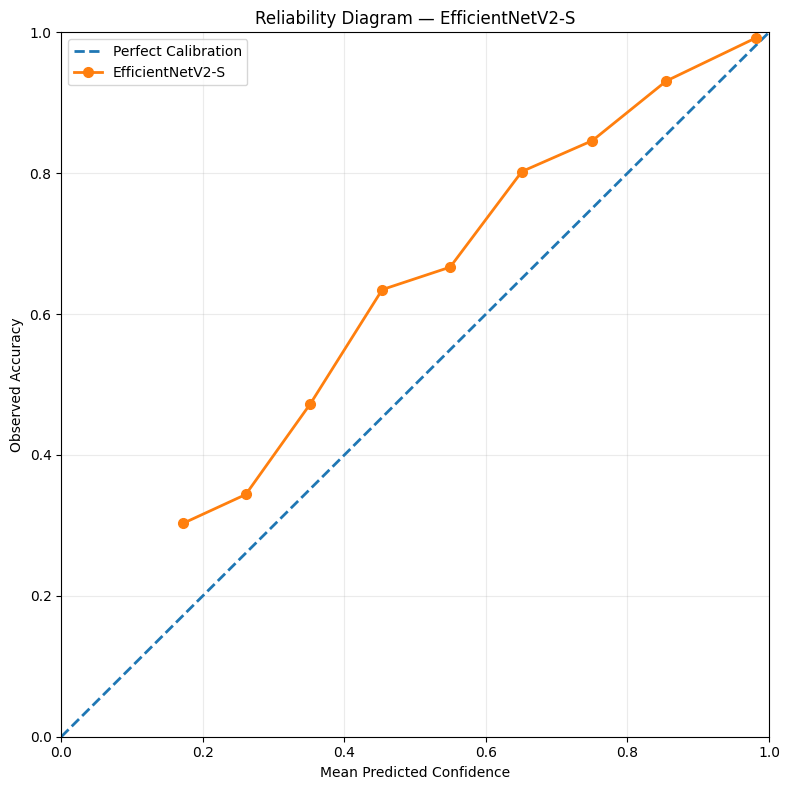

=== RELIABILITY DIAGRAM SAVED ===
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/calibration/reliability_diagram.png
ECE: 4.91%
MCE: 18.12%


In [ ]:
# ============================================================
# CALIBRATION — RELIABILITY DIAGRAM
# ============================================================

plt.figure(figsize=(8, 8))

# Perfect calibration line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Perfect Calibration"
)

# Keep only populated bins
plot_bins = calibration_bins.dropna(
    subset=["confidence", "accuracy"]
)

plt.plot(
    plot_bins["confidence"],
    plot_bins["accuracy"],
    marker="o",
    linewidth=2,
    markersize=7,
    label="EfficientNetV2-S"
)

plt.xlabel(
    "Mean Predicted Confidence"
)

plt.ylabel(
    "Observed Accuracy"
)

plt.title(
    "Reliability Diagram — EfficientNetV2-S"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()

RELIABILITY_FIG_PATH = os.path.join(
    CALIBRATION_DIR,
    "reliability_diagram.png"
)

plt.savefig(
    RELIABILITY_FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "=== RELIABILITY DIAGRAM SAVED ==="
)

print(
    "Path:",
    RELIABILITY_FIG_PATH
)

print(
    f"ECE: {ECE * 100:.2f}%"
)

print(
    f"MCE: {MCE * 100:.2f}%"
)

##Multiclass Brier Score

In [ ]:
# ============================================================
# CALIBRATION — MULTICLASS BRIER SCORE
# ============================================================

# One-hot encode the true labels
num_classes = all_probabilities.shape[1]

true_one_hot = F.one_hot(
    all_labels,
    num_classes=num_classes
).float()

# Multiclass Brier Score
brier_score = torch.mean(
    torch.sum(
        (all_probabilities - true_one_hot) ** 2,
        dim=1
    )
).item()

print("=== BRIER SCORE RESULTS ===")

print(
    "Number of classes:",
    num_classes
)

print(
    "Test samples:",
    len(all_labels)
)

print(
    "Multiclass Brier Score:",
    f"{brier_score:.6f}"
)

print(
    "\nInterpretation:"
)

print(
    "Lower Brier Score indicates better probabilistic prediction quality."
)


# ------------------------------------------------------------
# Update calibration summary
# ------------------------------------------------------------

calibration_summary["brier_score"] = float(
    brier_score
)

with open(
    CALIBRATION_SUMMARY_JSON,
    "w"
) as f:

    json.dump(
        calibration_summary,
        f,
        indent=4
    )


print(
    "\nCalibration summary updated successfully."
)

print(
    "Path:",
    CALIBRATION_SUMMARY_JSON
)

=== BRIER SCORE RESULTS ===
Number of classes: 38
Test samples: 10709
Multiclass Brier Score: 0.151807

Interpretation:
Lower Brier Score indicates better probabilistic prediction quality.

Calibration summary updated successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/calibration/calibration_summary.json


In [ ]:
# ============================================================
# FINAL CALIBRATION SUMMARY
# ============================================================

final_calibration_summary = {
    "experiment": {
        "name": "Clean Test Set Calibration Analysis",
        "model": "EfficientNetV2-S",
        "dataset": "PlantVillage RGB",
        "number_of_classes": 38,
        "test_samples": int(len(all_labels)),
        "number_of_bins": 10,
        "random_seed": 42
    },

    "classification_performance": {
        "accuracy": float(clean_accuracy),
        "accuracy_percent": float(clean_accuracy * 100),
        "macro_f1": float(clean_macro_f1),
        "macro_f1_percent": float(clean_macro_f1 * 100)
    },

    "calibration_metrics": {
        "mean_confidence": float(confidences.mean()),
        "mean_confidence_percent": float(
            confidences.mean() * 100
        ),
        "ece": float(ECE),
        "ece_percent": float(ECE * 100),
        "mce": float(MCE),
        "mce_percent": float(MCE * 100),
        "multiclass_brier_score": float(brier_score)
    },

    "interpretation": {
        "calibration_profile": (
            "Predominantly underconfident across populated "
            "confidence bins"
        ),
        "highest_confidence_bin_accuracy": float(
            plot_bins["accuracy"].iloc[-1]
        ),
        "highest_confidence_bin_confidence": float(
            plot_bins["confidence"].iloc[-1]
        )
    },

    "artifacts": {
        "calibration_bins_csv": CALIBRATION_RESULTS_CSV,
        "calibration_summary_json": CALIBRATION_SUMMARY_JSON,
        "reliability_diagram": RELIABILITY_FIG_PATH
    }
}


FINAL_CALIBRATION_JSON = os.path.join(
    CALIBRATION_DIR,
    "final_calibration_summary.json"
)

with open(
    FINAL_CALIBRATION_JSON,
    "w"
) as f:
    json.dump(
        final_calibration_summary,
        f,
        indent=4
    )


print("=== FINAL CALIBRATION SUMMARY ===")

print(
    f"Test Accuracy: "
    f"{clean_accuracy * 100:.2f}%"
)

print(
    f"Test Macro F1: "
    f"{clean_macro_f1 * 100:.2f}%"
)

print(
    f"Mean Confidence: "
    f"{confidences.mean() * 100:.2f}%"
)

print(
    f"ECE: "
    f"{ECE * 100:.2f}%"
)

print(
    f"MCE: "
    f"{MCE * 100:.2f}%"
)

print(
    f"Multiclass Brier Score: "
    f"{brier_score:.6f}"
)

print(
    "\nCalibration profile: "
    "Predominantly underconfident"
)

print(
    "\nFinal calibration summary saved successfully."
)

print(
    "Path:",
    FINAL_CALIBRATION_JSON
)

=== FINAL CALIBRATION SUMMARY ===
Test Accuracy: 90.16%
Test Macro F1: 88.00%
Mean Confidence: 85.25%
ECE: 4.91%
MCE: 18.12%
Multiclass Brier Score: 0.151807

Calibration profile: Predominantly underconfident

Final calibration summary saved successfully.
Path: /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/calibration/final_calibration_summary.json


##Final Experiment Audit

In [ ]:
# ============================================================
# FINAL EXPERIMENT AUDIT
# ============================================================

import os
import json
import pandas as pd

print("=== FINAL EXPERIMENT AUDIT ===")

# ------------------------------------------------------------
# Required experiment directories
# ------------------------------------------------------------

experiment_root = os.path.join(
    PROJECT_DIR,
    "experiments"
)

required_directories = {
    "Baseline": os.path.join(
        experiment_root,
        "efficientnetv2s_baseline"
    ),
    "Robustness": os.path.join(
        experiment_root,
        "robustness_evaluation"
    ),
    "Explainability": os.path.join(
        experiment_root,
        "explainability"
    ),
    "Calibration": os.path.join(
        experiment_root,
        "calibration"
    )
}

print("\n=== DIRECTORIES ===")

for name, path in required_directories.items():

    status = os.path.isdir(path)

    print(
        f"{name:20s}: "
        f"{'PASS' if status else 'MISSING'}"
    )

    print(
        f"  {path}"
    )


# ------------------------------------------------------------
# Required files
# ------------------------------------------------------------

required_files = {

    "Final model": os.path.join(
        experiment_root,
        "final_efficientnetv2s_plantvillage.pth"
    ),

    "Baseline results": os.path.join(
        experiment_root,
        "efficientnetv2s_baseline",
        "baseline_results.json"
    ),

    "Training history": os.path.join(
        experiment_root,
        "efficientnetv2s_baseline",
        "training_history.csv"
    ),

    "Robustness results": os.path.join(
        experiment_root,
        "robustness_evaluation",
        "robustness_results.csv"
    ),

    "Robustness analysis": os.path.join(
        experiment_root,
        "robustness_evaluation",
        "robustness_analysis.csv"
    ),

    "Robustness summary": os.path.join(
        experiment_root,
        "robustness_evaluation",
        "final_robustness_summary.json"
    ),

    "Calibration bins": os.path.join(
        experiment_root,
        "calibration",
        "calibration_bins.csv"
    ),

    "Calibration summary": os.path.join(
        experiment_root,
        "calibration",
        "calibration_summary.json"
    ),

    "Final calibration": os.path.join(
        experiment_root,
        "calibration",
        "final_calibration_summary.json"
    ),

    "Reliability diagram": os.path.join(
        experiment_root,
        "calibration",
        "reliability_diagram.png"
    ),

    "Grad-CAM overview": os.path.join(
        experiment_root,
        "explainability",
        "gradcam_representative_overview.png"
    ),

    "Grad-CAM errors": os.path.join(
        experiment_root,
        "explainability",
        "gradcam_misclassified_examples.png"
    )
}


print("\n=== REQUIRED ARTIFACTS ===")

audit_records = []

for name, path in required_files.items():

    exists = os.path.isfile(path)

    audit_records.append({
        "artifact": name,
        "exists": exists,
        "path": path
    })

    print(
        f"{name:25s}: "
        f"{'PASS' if exists else 'MISSING'}"
    )


audit_df = pd.DataFrame(
    audit_records
)


# ------------------------------------------------------------
# Load key results
# ------------------------------------------------------------

print("\n=== KEY RESULT CONSISTENCY ===")

print(
    f"Clean Accuracy: "
    f"{clean_accuracy * 100:.2f}%"
)

print(
    f"Clean Macro F1: "
    f"{clean_macro_f1 * 100:.2f}%"
)

print(
    f"ECE: "
    f"{ECE * 100:.2f}%"
)

print(
    f"MCE: "
    f"{MCE * 100:.2f}%"
)

print(
    f"Brier Score: "
    f"{brier_score:.6f}"
)


# ------------------------------------------------------------
# Overall audit status
# ------------------------------------------------------------

all_directories_ok = all(
    os.path.isdir(path)
    for path in required_directories.values()
)

all_files_ok = all(
    os.path.isfile(path)
    for path in required_files.values()
)

overall_pass = (
    all_directories_ok
    and all_files_ok
)

print("\n=== AUDIT STATUS ===")

if overall_pass:

    print(
        "RESULT: PASS — all required experiment "
        "artifacts are present."
    )

else:

    print(
        "RESULT: REVIEW REQUIRED — one or more "
        "artifacts are missing."
    )

print(
    "\nFinal model:",
    os.path.join(
        experiment_root,
        "final_efficientnetv2s_plantvillage.pth"
    )
)

=== FINAL EXPERIMENT AUDIT ===

=== DIRECTORIES ===
Baseline            : PASS
  /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/efficientnetv2s_baseline
Robustness          : PASS
  /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/robustness_evaluation
Explainability      : PASS
  /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/explainability
Calibration         : PASS
  /content/drive/MyDrive/Robust_Crop_Disease_Screening/experiments/calibration

=== REQUIRED ARTIFACTS ===
Final model              : PASS
Baseline results         : PASS
Training history         : PASS
Robustness results       : PASS
Robustness analysis      : PASS
Robustness summary       : PASS
Calibration bins         : PASS
Calibration summary      : PASS
Final calibration        : PASS
Reliability diagram      : PASS
Grad-CAM overview        : PASS
Grad-CAM errors          : PASS

=== KEY RESULT CONSISTENCY ===
Clean Accuracy: 90.16%
Clean Macro F1: 88.00%
ECE: 4.9